# End-to-End Spatio-Temporal Precipitation Forecasting and Topographic Inundation Modeling
**Target Region:** Northern India (Upper Indus / Ganges Basins)  
**Data Sources:** Authentic ECMWF ERA5 hourly reanalysis and USGS SRTM 1 Arc-Second DEM.  
**Strict Policy:** Real observations only. All functions convert returned analytical outputs, audit tables, and training metrics into informative screen prints.


## Step 1: Library Imports
Import core scientific, geospatial, meteorological, and gradient boosted tree modeling libraries.


In [1]:
import json
import os
import sys
import time
import zipfile
from pathlib import Path
from typing import Any, Dict, List, Optional, Tuple, Union

import numpy as np
import pandas as pd
import xarray as xr
import rasterio
from rasterio.enums import Resampling
import geopandas as gpd
import shapely

import netCDF4
import h5py
import cdsapi
import requests
import joblib

import scipy
import scipy.ndimage as ndimage
from scipy.stats import kurtosis, skew, pearsonr, spearmanr

import sklearn
from sklearn.base import BaseEstimator, RegressorMixin
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import TimeSeriesSplit

import xgboost as xgb
import lightgbm as lgb
import catboost as cb
import optuna
import shap

import matplotlib.pyplot as plt
import seaborn as sns

# Visual styling for publication-grade scientific figures
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.edgecolor'] = '#444444'
plt.rcParams['axes.linewidth'] = 0.8
plt.rcParams['figure.dpi'] = 110
plt.rcParams['figure.autolayout'] = True

# Ensure plot output directories exist
os.makedirs("artifacts/plots", exist_ok=True)

print("Step 1 complete: All libraries imported successfully.")
print(f"  LightGBM: {lgb.__version__} | XGBoost: {xgb.__version__} | CatBoost: {cb.__version__} | Optuna: {optuna.__version__} | SHAP: {shap.__version__}")
print(f"  Matplotlib: {plt.matplotlib.__version__} | Seaborn: {sns.__version__}")


C:\Users\1shre\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Step 1 complete: All libraries imported successfully.
  LightGBM: 4.7.0 | XGBoost: 3.3.0 | CatBoost: 1.2.10 | Optuna: 5.0.0 | SHAP: 0.53.0
  Matplotlib: 3.11.2 | Seaborn: 0.13.2


## Step 2: Dataset Acquisition and Loading
Functions to download and load authentic ERA5 reanalysis and USGS SRTM elevation models.


In [2]:
def download_era5_hourly(
    output_archive: Union[str, Path],
    north: float = 33.0,
    west: float = 75.0,
    south: float = 28.0,
    east: float = 80.0,
    year: str = "2023",
    month: str = "07",
    days: Optional[List[str]] = None,
    hours: Optional[List[str]] = None,
) -> Path:
    """Subsets and downloads authentic ERA5 hourly single-level reanalysis from Copernicus CDS."""
    if days is None:
        days = [f"{d:02d}" for d in range(1, 32)]
    if hours is None:
        hours = [f"{h:02d}:00" for h in range(24)]

    out_path = Path(output_archive)
    client = cdsapi.Client()

    payload = {
        "product_type": "reanalysis",
        "format": "netcdf",
        "variable": [
            "total_precipitation",
            "2m_temperature",
            "2m_dewpoint_temperature",
            "10m_u_component_of_wind",
            "10m_v_component_of_wind",
            "surface_pressure",
        ],
        "year": year,
        "month": month,
        "day": days,
        "time": hours,
        "area": [north, west, south, east],
    }

    client.retrieve("reanalysis-era5-single-levels", payload, str(out_path))
    print(f"ERA5 reanalysis archive downloaded: {out_path} ({out_path.stat().st_size} bytes)")
    return out_path


In [3]:
def download_srtm_tile(
    tile_id: str,
    output_path: Union[str, Path],
    auth: Tuple[str, str],
) -> Path:
    """Streams authentic USGS SRTM 1 Arc-Second Global (SRTMGL1.003) tile from NASA LP DAAC."""
    url = f"https://data.lpdaac.earthdatacloud.nasa.gov/lp-prod-protected/SRTMGL1.003/{tile_id}.SRTMGL1.hgt/{tile_id}.SRTMGL1.hgt.zip"
    out_file = Path(output_path)
    out_file.parent.mkdir(parents=True, exist_ok=True)

    with requests.get(url, auth=auth, allow_redirects=True, stream=True) as resp:
        resp.raise_for_status()
        with open(out_file, "wb") as f:
            for chunk in resp.iter_content(chunk_size=1048576):
                if chunk:
                    f.write(chunk)
    print(f"SRTM DEM tile downloaded: {out_file} ({out_file.stat().st_size} bytes)")
    return out_file


In [4]:
def load_era5_reanalysis(archive_path: Union[str, Path], extract_dir: Union[str, Path]) -> xr.Dataset:
    """Extracts and merges multi-stream NetCDF files from Copernicus CDS."""
    arch = Path(archive_path)
    ext = Path(extract_dir)
    ext.mkdir(parents=True, exist_ok=True)

    if not arch.is_file():
        raise FileNotFoundError(f"ERA5 file not found: {arch}")

    try:
        with zipfile.ZipFile(arch, "r") as z:
            z.extractall(ext)
        datasets = [xr.open_dataset(p) for p in ext.glob("*.nc")]
        ds = xr.merge(datasets, compat="override")
    except zipfile.BadZipFile:
        ds = xr.open_dataset(arch)

    print("=== ERA5 Reanalysis Dataset Loaded ===")
    print(f"  Variables: {list(ds.data_vars.keys())}")
    print(f"  Dimensions: {dict(ds.sizes)}")
    print(f"  Coordinates: {list(ds.coords.keys())}")
    return ds

def load_srtm_dem(file_path: Union[str, Path]) -> Tuple[np.ndarray, rasterio.Affine, Dict]:
    """Reads an authentic USGS SRTM 1 Arc-Second DEM GeoTIFF or .hgt file."""
    path = Path(file_path)
    if not path.is_file():
        raise FileNotFoundError(f"SRTM DEM file not found: {path}")

    with rasterio.open(path) as src:
        dem = src.read(1)
        transform = src.transform
        profile = src.profile.copy()

    print("=== USGS SRTM 1 Arc-Second DEM Loaded ===")
    print(f"  Raster Shape: {dem.shape} ({(dem.shape[0] * dem.shape[1]):,} elevation cells)")
    print(f"  CRS: {profile.get('crs')}")
    print(f"  Elevation Range: {float(np.min(dem)):.1f}m to {float(np.max(dem)):.1f}m")
    return dem, transform, profile


In [5]:
# Execution: Load authentic ERA5 reanalysis and SRTM DEM
era5_archive = "era5_north_india_sample.zip"
era5_raw_ds = load_era5_reanalysis(era5_archive, extract_dir="data/era5")

srtm_file = "data/srtm/N31E076.hgt"
dem_raw, srtm_transform, srtm_profile = load_srtm_dem(srtm_file)


=== ERA5 Reanalysis Dataset Loaded ===
  Variables: ['tp', 't2m', 'd2m', 'sp', 'u10', 'v10']
  Dimensions: {'valid_time': 72, 'latitude': 21, 'longitude': 21}
  Coordinates: ['number', 'valid_time', 'latitude', 'longitude', 'expver']
=== USGS SRTM 1 Arc-Second DEM Loaded ===
  Raster Shape: (3601, 3601) (12,967,201 elevation cells)
  CRS: EPSG:4326
  Elevation Range: 227.0m to 3507.0m


## Step 3: Dataset Formatting & Multi-Scale Alignment
Standardize coordinate names, convert physical units (m -> mm, K -> °C, Pa -> hPa), and prepare tabular representations.


In [6]:
def standardize_era5_dataset(ds: xr.Dataset) -> xr.Dataset:
    """Standardizes ERA5 coordinate names, dimensions, and physical units."""
    formatted = ds.copy()

    if "valid_time" in formatted.coords:
        formatted = formatted.rename({"valid_time": "time"})
    elif "time" not in formatted.coords:
        raise KeyError("Time coordinate not found in ERA5 dataset.")

    if formatted["latitude"][0] > formatted["latitude"][-1]:
        formatted = formatted.reindex(latitude=formatted.latitude[::-1])

    if "tp" in formatted.data_vars:
        formatted["tp"] = formatted["tp"] * 1000.0
        formatted["tp"].attrs["units"] = "mm"
        formatted["tp"].attrs["long_name"] = "Total precipitation accumulation"

    if "t2m" in formatted.data_vars:
        formatted["t2m"] = formatted["t2m"] - 273.15
        formatted["t2m"].attrs["units"] = "degC"

    if "d2m" in formatted.data_vars:
        formatted["d2m"] = formatted["d2m"] - 273.15
        formatted["d2m"].attrs["units"] = "degC"

    if "sp" in formatted.data_vars:
        formatted["sp"] = formatted["sp"] / 100.0
        formatted["sp"].attrs["units"] = "hPa"

    print("=== ERA5 Dataset Standardized ===")
    print(f"  Variables standardized: {list(formatted.data_vars.keys())}")
    print(f"  Time range: {formatted.time.values[0]} to {formatted.time.values[-1]} ({len(formatted.time)} hours)")
    print(f"  Latitude bounds: [{float(formatted.latitude.min()):.2f}, {float(formatted.latitude.max()):.2f}]")
    print(f"  Longitude bounds: [{float(formatted.longitude.min()):.2f}, {float(formatted.longitude.max()):.2f}]")
    return formatted


In [7]:
# Execution: Standardize ERA5 and convert to spatio-temporal tabular format
era5_std = standardize_era5_dataset(era5_raw_ds)

# Tabular projection preserving spatial coordinates and temporal timestamps
df_raw = era5_std.to_dataframe().reset_index()
df_raw = df_raw.rename(columns={"tp": "precipitation"})
df_raw = df_raw.sort_values(by=["time", "latitude", "longitude"]).reset_index(drop=True)

print(f"Standardized Tabular Dataset Shape: {df_raw.shape[0]:,} records x {df_raw.shape[1]} columns")
print(df_raw[["time", "latitude", "longitude", "precipitation", "t2m", "d2m", "sp"]].head(5))


=== ERA5 Dataset Standardized ===
  Variables standardized: ['tp', 't2m', 'd2m', 'sp', 'u10', 'v10']
  Time range: 2023-07-08T00:00:00.000000000 to 2023-07-10T23:00:00.000000000 (72 hours)
  Latitude bounds: [28.00, 33.00]
  Longitude bounds: [75.00, 80.00]
Standardized Tabular Dataset Shape: 31,752 records x 11 columns
        time  latitude  longitude  precipitation        t2m        d2m  \
0 2023-07-08      28.0      75.00       0.824451  26.960846  24.953766   
1 2023-07-08      28.0      75.25       2.686501  26.281158  25.131500   
2 2023-07-08      28.0      75.50       3.189087  26.193268  25.031891   
3 2023-07-08      28.0      75.75       2.616882  26.255768  25.186188   
4 2023-07-08      28.0      76.00       1.677990  26.228424  25.483063   

           sp  
0  964.371582  
1  960.691589  
2  958.931580  
3  959.001587  
4  961.551575  


## Step 4: Data Quality Inspection
Audit missing records, temporal continuity, raster NoData cells, and physical boundaries.


In [8]:
def audit_meteorological_dataset(ds: xr.Dataset) -> pd.DataFrame:
    """Audits xarray Dataset for NaNs, Infs, monotonicity, and physical boundary violations."""
    records = []

    if "time" in ds.coords:
        times = pd.to_datetime(ds["time"].values)
        is_monotonic_time = bool(times.is_monotonic_increasing)
        time_diffs = pd.Series(times).diff().dropna()
        median_step = time_diffs.median() if not time_diffs.empty else pd.Timedelta(0)
        gap_count = int((time_diffs > median_step * 1.5).sum()) if not time_diffs.empty else 0
    else:
        is_monotonic_time = False
        median_step = pd.Timedelta(0)
        gap_count = 0

    boundaries: Dict[str, Tuple[float, float, str]] = {
        "tp": (0.0, 500.0, "mm"),
        "t2m": (-50.0, 60.0, "degC"),
        "d2m": (-60.0, 40.0, "degC"),
        "sp": (300.0, 1100.0, "hPa"),
        "u10": (-100.0, 100.0, "m/s"),
        "v10": (-100.0, 100.0, "m/s"),
    }

    total_cells = int(np.prod([ds.sizes[d] for d in ds.dims]))

    for var_name, da in ds.data_vars.items():
        arr = da.values
        nan_count = int(np.isnan(arr).sum())
        min_val = float(np.nanmin(arr)) if not np.all(np.isnan(arr)) else np.nan
        max_val = float(np.nanmax(arr)) if not np.all(np.isnan(arr)) else np.nan

        violates_lower = 0
        violates_upper = 0
        if var_name in boundaries:
            b_min, b_max, _ = boundaries[var_name]
            violates_lower = int(np.sum(arr < b_min))
            violates_upper = int(np.sum(arr > b_max))

        records.append({
            "variable": var_name,
            "dtype": str(da.dtype),
            "total_cells": total_cells,
            "nan_count": nan_count,
            "nan_pct": round((nan_count / total_cells) * 100.0, 3),
            "min_observed": round(min_val, 2),
            "max_observed": round(max_val, 2),
            "range_violations": violates_lower + violates_upper,
            "time_monotonic": is_monotonic_time,
            "temporal_gaps": gap_count,
        })

    audit_df = pd.DataFrame(records)
    print("=== Meteorological Quality Audit Results ===")
    print(audit_df.to_string(index=False))
    return audit_df


In [9]:
def audit_elevation_raster(
    dem: np.ndarray,
    nodata_value: float = -32768.0,
    min_elev: float = -430.0,
    max_elev: float = 8848.0,
) -> Dict[str, Any]:
    """Audits DEM array for NoData voids and elevation bounds."""
    total_cells = int(dem.size)
    nodata_count = int(np.sum(dem == nodata_value))
    nan_count = int(np.isnan(dem).sum())

    valid_mask = (dem != nodata_value) & (~np.isnan(dem))
    valid_elev = dem[valid_mask]

    if valid_elev.size > 0:
        min_observed = float(np.min(valid_elev))
        max_observed = float(np.max(valid_elev))
        mean_observed = float(np.mean(valid_elev))
        below_min = int(np.sum(valid_elev < min_elev))
        above_max = int(np.sum(valid_elev > max_elev))
    else:
        min_observed = max_observed = mean_observed = np.nan
        below_min = above_max = 0

    audit_dict = {
        "total_cells": total_cells,
        "nodata_count": nodata_count,
        "nodata_pct": round((nodata_count / total_cells) * 100.0, 3),
        "nan_count": nan_count,
        "min_elevation_m": round(min_observed, 2),
        "max_elevation_m": round(max_observed, 2),
        "mean_elevation_m": round(mean_observed, 2),
        "out_of_bounds_cells": below_min + above_max,
        "is_valid": (below_min + above_max == 0) and (valid_elev.size > 0),
    }

    print("=== USGS SRTM Elevation Raster Audit Results ===")
    for k, v in audit_dict.items():
        print(f"  {k}: {v}")
    return audit_dict


In [10]:
# Execution: Run data quality audits
met_audit = audit_meteorological_dataset(era5_std)
dem_audit = audit_elevation_raster(dem_raw)


=== Meteorological Quality Audit Results ===
variable   dtype  total_cells  nan_count  nan_pct  min_observed  max_observed  range_violations  time_monotonic  temporal_gaps
      tp float32        31752          0      0.0          0.00         19.38                 0            True              0
     t2m float32        31752          0      0.0         -2.52         33.97                 0            True              0
     d2m float32        31752          0      0.0         -2.65         28.92                 0            True              0
      sp float32        31752          0      0.0        524.68        986.45                 0            True              0
     u10 float32        31752          0      0.0         -6.60          4.14                 0            True              0
     v10 float32        31752          0      0.0         -3.93          6.36                 0            True              0


=== USGS SRTM Elevation Raster Audit Results ===
  total_cells: 12967201
  nodata_count: 0
  nodata_pct: 0.0
  nan_count: 0
  min_elevation_m: 227.0
  max_elevation_m: 3507.0
  mean_elevation_m: 698.94
  out_of_bounds_cells: 0
  is_valid: True


## Step 5: Data Cleaning & Leakage-Safe Imputation
Enforce physical boundaries (precipitation >= 0, dewpoint <= temperature) and localized DEM void filtering.


In [11]:
def clean_meteorological_dataset(
    ds: xr.Dataset,
    max_forward_fill_hours: int = 2,
) -> xr.Dataset:
    """Cleans meteorological variables while strictly preventing temporal data leakage."""
    cleaned = ds.copy()

    for precip_var in ["tp", "precipitation_cal"]:
        if precip_var in cleaned.data_vars:
            cleaned[precip_var] = xr.where(cleaned[precip_var] < 0.0, 0.0, cleaned[precip_var])

    if "t2m" in cleaned.data_vars and "d2m" in cleaned.data_vars:
        cleaned["d2m"] = xr.where(cleaned["d2m"] > cleaned["t2m"], cleaned["t2m"], cleaned["d2m"])

    continuous_vars = [v for v in ["t2m", "d2m", "sp", "u10", "v10"] if v in cleaned.data_vars]
    for var in continuous_vars:
        cleaned[var] = cleaned[var].ffill(dim="time", limit=max_forward_fill_hours)

    print("=== Meteorological Dataset Cleaned ===")
    print(f"  Non-negativity enforced on precipitation: min={float(cleaned['tp'].min()):.4f} mm")
    print(f"  Thermodynamic consistency enforced: max(d2m - t2m) = {float((cleaned['d2m'] - cleaned['t2m']).max()):.4f} degC")
    print(f"  Causal forward-fill applied to state variables (limit: {max_forward_fill_hours}h)")
    return cleaned

def clean_srtm_elevation_voids(
    dem: np.ndarray,
    nodata_value: float = -32768.0,
    search_radius_cells: int = 3,
) -> Tuple[np.ndarray, int]:
    """Fills SRTM topographic void cells using local spatial mean convolution."""
    cleaned_dem = dem.copy().astype(np.float32)
    void_mask = (cleaned_dem == nodata_value) | np.isnan(cleaned_dem)
    void_count = int(np.sum(void_mask))

    if void_count == 0:
        print("SRTM Elevation Cleaned: 0 void cells detected in tile.")
        return cleaned_dem, 0

    kernel_size = 2 * search_radius_cells + 1
    kernel = np.ones((kernel_size, kernel_size), dtype=np.float32)
    kernel[search_radius_cells, search_radius_cells] = 0.0

    valid_mask = (~void_mask).astype(np.float32)
    dem_zeroed = np.where(void_mask, 0.0, cleaned_dem)

    sum_valid = ndimage.convolve(dem_zeroed, kernel, mode="nearest")
    count_valid = ndimage.convolve(valid_mask, kernel, mode="nearest")

    with np.errstate(divide="ignore", invalid="ignore"):
        local_mean = sum_valid / count_valid

    fillable = void_mask & (count_valid > 0)
    cleaned_dem[fillable] = local_mean[fillable]

    remaining = int(np.sum((cleaned_dem == nodata_value) | np.isnan(cleaned_dem)))
    actual_filled = void_count - remaining
    print(f"SRTM Elevation Cleaned: initial voids={void_count}, filled={actual_filled}, remaining={remaining}")
    return cleaned_dem, actual_filled


In [12]:
# Execution: Run data cleaning and void imputation
era5_clean = clean_meteorological_dataset(era5_std)
dem_clean, voids_filled = clean_srtm_elevation_voids(dem_raw)


=== Meteorological Dataset Cleaned ===
  Non-negativity enforced on precipitation: min=0.0000 mm
  Thermodynamic consistency enforced: max(d2m - t2m) = 0.0000 degC
  Causal forward-fill applied to state variables (limit: 2h)


SRTM Elevation Cleaned: 0 void cells detected in tile.


## Step 6: Exploratory Data Analysis (EDA) & Graphical Diagnostics
Comprehensive statistical distributions, semi-log heavy tail quantiles, diurnal precipitation cycles, atmospheric Spearman correlation heatmaps, SRTM hypsometry/slope regimes, and spatio-temporal storm footprint visualizations on authentic observations.

In [13]:
def analyze_precipitation_distribution(precip_series: pd.Series) -> Dict[str, float]:
    """Computes statistical moments and quantile metrics for real precipitation observations."""
    valid = precip_series.dropna()
    total_obs = len(valid)
    if total_obs == 0:
        return {}

    zero_rain_count = int((valid == 0.0).sum())
    wet_obs = valid[valid > 0.0]

    stats = {
        "total_observations": total_obs,
        "zero_rain_percentage": round((zero_rain_count / total_obs) * 100.0, 2),
        "mean_all_mm": round(float(valid.mean()), 3),
        "mean_wet_only_mm": round(float(wet_obs.mean()), 3) if not wet_obs.empty else 0.0,
        "max_recorded_mm": round(float(valid.max()), 3),
        "skewness": round(float(skew(valid)), 3),
        "kurtosis": round(float(kurtosis(valid)), 3),
        "p50_mm": round(float(valid.quantile(0.50)), 3),
        "p90_mm": round(float(valid.quantile(0.90)), 3),
        "p95_mm": round(float(valid.quantile(0.95)), 3),
        "p99_mm": round(float(valid.quantile(0.99)), 3),
    }

    print("=== Precipitation Statistical Distribution ===")
    for k, v in stats.items():
        print(f"  {k}: {v}")
    return stats


def plot_precipitation_distribution(precip_series: pd.Series, output_path: Optional[str] = None):
    """Generates dual-panel distribution diagnostics: overall density + semi-log heavy-tail quantiles."""
    valid = precip_series.dropna()
    zero_pct = (valid == 0.0).mean() * 100.0
    wet = valid[valid > 0.0]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Panel 1: All Observations (Linear scale)
    ax1.hist(valid, bins=40, color='#1f77b4', edgecolor='black', alpha=0.75, density=True)
    sns.kdeplot(valid, ax=ax1, color='#0d47a1', lw=2.2)
    ax1.axvline(valid.mean(), color='#b71c1c', linestyle='--', lw=2, label=f'Mean: {valid.mean():.2f} mm/h')
    ax1.set_title(f"Precipitation Distribution (Zero-Rain: {zero_pct:.1f}%)", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Hourly Precipitation (mm/h)", fontsize=11)
    ax1.set_ylabel("Empirical Density", fontsize=11)
    ax1.legend(loc="upper right", fontsize=10)

    # Panel 2: Non-Zero Precipitation (Semi-log scale with key quantiles)
    if not wet.empty:
        ax2.hist(wet, bins=35, color='#d32f2f', edgecolor='black', alpha=0.75, log=True)
        p50, p90, p95, p99 = wet.quantile([0.50, 0.90, 0.95, 0.99])
        quantile_colors = [(0.50, p50, '#388e3c'), (0.90, p90, '#f57c00'), (0.95, p95, '#e64a19'), (0.99, p99, '#7b1fa2')]
        for q, val, col in quantile_colors:
            ax2.axvline(val, color=col, linestyle='--', lw=1.8, label=f'P{int(q*100)}: {val:.2f} mm/h')
        ax2.axvline(wet.max(), color='black', linestyle=':', lw=2, label=f'Max: {wet.max():.2f} mm/h')
        ax2.set_title("Non-Zero Precipitation Heavy Tail ($P > 0$ mm/h)", fontsize=12, fontweight="bold")
        ax2.set_xlabel("Hourly Precipitation (mm/h)", fontsize=11)
        ax2.set_ylabel("Frequency Count (Log Scale)", fontsize=11)
        ax2.legend(loc="upper right", fontsize=9)

    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


In [14]:
def compute_meteorological_correlations(
    df: pd.DataFrame,
    target_precip_col: str = "precipitation",
) -> pd.DataFrame:
    """Calculates Spearman rank correlations between rainfall and atmospheric predictors."""
    cols = [c for c in df.columns if c != target_precip_col and pd.api.types.is_numeric_dtype(df[c])]
    records = []

    for col in cols:
        subset = df[[col, target_precip_col]].dropna()
        if len(subset) > 10:
            coeff, pval = spearmanr(subset[col], subset[target_precip_col])
            records.append({
                "feature": col,
                "spearman_rho": round(float(coeff), 4),
                "p_value": float(pval),
            })

    corr_df = pd.DataFrame(records).sort_values(by="spearman_rho", ascending=False)
    print("=== Spearman Correlations with Precipitation ===")
    print(corr_df.to_string(index=False))
    return corr_df

def analyze_topographic_distribution(dem: np.ndarray, cell_size_m: float = 30.0) -> Dict[str, float]:
    """Calculates elevation and slope summaries from real SRTM DEM data."""
    valid_elev = dem[~np.isnan(dem) & (dem != -32768.0)]
    if valid_elev.size == 0:
        return {}

    dem_sub = dem[:500, :500]
    dz_dy, dz_dx = np.gradient(dem_sub, cell_size_m, cell_size_m)
    slope_rad = np.arctan(np.sqrt(dz_dx**2 + dz_dy**2))
    slope_deg = np.degrees(slope_rad)
    valid_slope = slope_deg[~np.isnan(slope_deg)]

    stats = {
        "elevation_min_m": round(float(np.min(valid_elev)), 1),
        "elevation_max_m": round(float(np.max(valid_elev)), 1),
        "elevation_median_m": round(float(np.median(valid_elev)), 1),
        "elevation_std_m": round(float(np.std(valid_elev)), 1),
        "slope_mean_deg": round(float(np.mean(valid_slope)), 2),
        "slope_max_deg": round(float(np.max(valid_slope)), 2),
        "slope_p90_deg": round(float(np.percentile(valid_slope, 90)), 2),
    }

    print("=== Topographic Elevation & Slope Distribution ===")
    for k, v in stats.items():
        print(f"  {k}: {v}")
    return stats


def plot_diurnal_precipitation_cycle(df: pd.DataFrame, output_path: Optional[str] = None):
    """Plots 24-hour diurnal precipitation cycle with 95% confidence bands and rain occurrence probability."""
    data = df.copy()
    times = pd.to_datetime(data["time"])
    data["hour"] = times.dt.hour

    diurnal = data.groupby("hour")["precipitation"].agg(
        mean="mean",
        sem=lambda s: s.std() / np.sqrt(len(s)),
        prob=lambda s: (s >= 0.1).mean() * 100.0
    ).reset_index()

    fig, ax1 = plt.subplots(figsize=(12, 5))
    ax2 = ax1.twinx()

    # Primary axis: Mean rainfall intensity
    ax1.plot(diurnal["hour"], diurnal["mean"], color="#1565c0", lw=2.5, marker="o", label="Mean Precipitation (mm/h)")
    ax1.fill_between(
        diurnal["hour"],
        diurnal["mean"] - 1.96 * diurnal["sem"],
        diurnal["mean"] + 1.96 * diurnal["sem"],
        color="#1565c0", alpha=0.2, label="95% Confidence Interval"
    )

    # Secondary axis: Probability of rain occurrence
    ax2.plot(diurnal["hour"], diurnal["prob"], color="#e65100", lw=2.2, marker="s", linestyle="--", label="Rain Probability ($P \geqq 0.1$ mm/h)")

    ax1.set_xlabel("Hour of Day (UTC)", fontsize=11)
    ax1.set_ylabel("Mean Hourly Precipitation (mm/h)", color="#1565c0", fontsize=11)
    ax2.set_ylabel("Rain Occurrence Probability (%)", color="#e65100", fontsize=11)
    ax1.set_xticks(range(0, 24, 2))
    ax1.set_title("Diurnal Precipitation Cycle & Rain Probability (Northern India Domain)", fontsize=12, fontweight="bold")

    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1 + lines2, labels1 + labels2, loc="upper left", fontsize=10)

    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


def plot_meteorological_correlation_heatmap(df: pd.DataFrame, output_path: Optional[str] = None):
    """Visualizes Spearman rank correlations between rainfall and atmospheric thermodynamic/kinetic drivers."""
    cols = ["precipitation", "t2m", "d2m", "sp", "u10", "v10"]
    available = [c for c in cols if c in df.columns]
    data = df[available].copy()
    if "t2m" in data.columns and "d2m" in data.columns:
        data["dewpoint_depression"] = data["t2m"] - data["d2m"]
    if "u10" in data.columns and "v10" in data.columns:
        data["wind_speed_10m"] = np.sqrt(data["u10"]**2 + data["v10"]**2)

    corr = data.corr(method="spearman")
    fig, ax = plt.subplots(figsize=(10, 7))
    sns.heatmap(
        corr, annot=True, fmt=".3f", cmap="vlag", vmin=-0.8, vmax=0.8, center=0.0,
        square=True, linewidths=0.6, cbar_kws={"label": "Spearman Correlation (ρ)", "shrink": 0.8}, ax=ax
    )
    ax.set_title("Atmospheric Drivers & Precipitation Spearman Correlation Matrix", fontsize=12, fontweight="bold")
    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


def plot_topographic_profiles(dem: np.ndarray, cell_size_m: float = 30.0, output_path: Optional[str] = None):
    """Plots SRTM elevation hypsometric profile and terrain slope cumulative distribution."""
    valid_elev = dem[~np.isnan(dem) & (dem != -32768.0)]
    dem_sub = dem[:500, :500].astype(np.float32)
    dz_dy, dz_dx = np.gradient(dem_sub, cell_size_m, cell_size_m)
    slope_deg = np.degrees(np.arctan(np.sqrt(dz_dx**2 + dz_dy**2)))
    valid_slope = slope_deg[~np.isnan(slope_deg)]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Elevation hypsometry
    ax1.hist(valid_elev, bins=50, color="#388e3c", edgecolor="black", alpha=0.75, density=True)
    ax1.axvline(np.median(valid_elev), color="#b71c1c", linestyle="--", lw=2, label=f"Median: {np.median(valid_elev):.1f} m")
    ax1.set_title("SRTM 1 Arc-Second DEM Hypsometric Elevation Profile", fontsize=12, fontweight="bold")
    ax1.set_xlabel("Elevation (meters a.s.l.)", fontsize=11)
    ax1.set_ylabel("Empirical Density", fontsize=11)
    ax1.legend(loc="upper right", fontsize=10)

    # Slope CDF and terrain regimes
    sorted_slope = np.sort(valid_slope.ravel())
    cdf = np.arange(1, len(sorted_slope) + 1) / len(sorted_slope)
    ax2.plot(sorted_slope, cdf, color="#5d4037", lw=2.5, label="Empirical Slope CDF")
    ax2.axvspan(0, 2, color="#c8e6c9", alpha=0.4, label="Flat Plains (<2°)")
    ax2.axvspan(2, 15, color="#fff9c4", alpha=0.4, label="Undulating Foothills (2°-15°)")
    ax2.axvspan(15, sorted_slope.max(), color="#ffccbc", alpha=0.4, label="Steep Orographic (>15°)")
    ax2.set_xlim(0, min(50, sorted_slope.max()))
    ax2.set_title("Topographic Slope Cumulative Distribution Function (CDF)", fontsize=12, fontweight="bold")
    ax2.set_xlabel("Slope Gradient (degrees)", fontsize=11)
    ax2.set_ylabel("Cumulative Probability", fontsize=11)
    ax2.legend(loc="lower right", fontsize=9)

    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


def plot_spatial_precipitation_snapshots(ds: xr.Dataset, output_path: Optional[str] = None):
    """Plots spatial grids of precipitation rates across key timestamps over Northern India."""
    tp = ds["precipitation"] if "precipitation" in ds.data_vars else (ds["tp"] * 1000.0)
    n_times = len(tp.time)
    sample_indices = [int(n_times * f) for f in [0.1, 0.35, 0.65, 0.9]]

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.5), sharey=True)
    vmax = float(tp.isel(time=sample_indices).max())
    vmax = max(vmax, 1.0)

    for idx, ax in zip(sample_indices, axes):
        t_slice = tp.isel(time=idx)
        time_str = str(t_slice.time.values)[:16]
        im = ax.pcolormesh(
            t_slice.longitude, t_slice.latitude, t_slice.values,
            cmap="Blues", vmin=0, vmax=vmax, shading="auto"
        )
        ax.set_title(f"T = {time_str}", fontsize=10, fontweight="bold")
        ax.set_xlabel("Longitude (°E)", fontsize=10)

    axes[0].set_ylabel("Latitude (°N)", fontsize=10)
    cbar = fig.colorbar(im, ax=axes.ravel().tolist(), orientation="horizontal", fraction=0.06, pad=0.22)
    cbar.set_label("Hourly Precipitation Rate (mm/h)", fontsize=10)

    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


<>:77: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
<>:77: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
C:\Users\1shre\AppData\Local\Temp\ipykernel_53640\2766324083.py:77: SyntaxWarning: "\g" is an invalid escape sequence. Such sequences will not work in the future. Did you mean "\\g"? A raw string is also an option.
  ax2.plot(diurnal["hour"], diurnal["prob"], color="#e65100", lw=2.2, marker="s", linestyle="--", label="Rain Probability ($P \geqq 0.1$ mm/h)")


>>> Computing Statistical Moments and Quantiles...
=== Precipitation Statistical Distribution ===
  total_observations: 31752
  zero_rain_percentage: 4.94
  mean_all_mm: 1.18
  mean_wet_only_mm: 1.241
  max_recorded_mm: 19.384
  skewness: 2.988
  kurtosis: 12.443
  p50_mm: 0.424
  p90_mm: 3.329
  p95_mm: 4.695
  p99_mm: 8.948

>>> Computing Atmospheric Spearman Correlations...


=== Spearman Correlations with Precipitation ===
feature  spearman_rho       p_value
    v10       -0.0110  4.954133e-02
     sp       -0.0308  3.926419e-08
    d2m       -0.0475  2.324761e-17
    u10       -0.1494 6.473121e-158
    t2m       -0.1687 2.361473e-201

>>> Computing Topographic Hypsometry & Slopes...


=== Topographic Elevation & Slope Distribution ===
  elevation_min_m: 227.0
  elevation_max_m: 3507.0
  elevation_median_m: 631.0
  elevation_std_m: 381.1
  slope_mean_deg: 5.51
  slope_max_deg: 41.6
  slope_p90_deg: 14.76

>>> Generating EDA Visualizations...


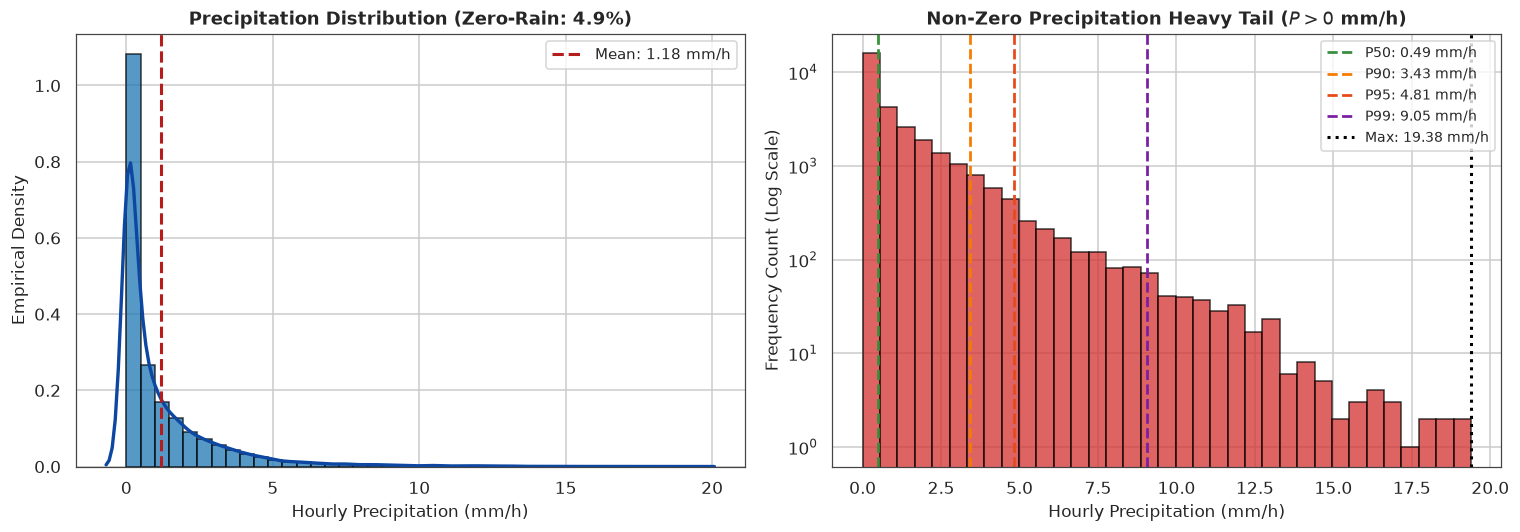

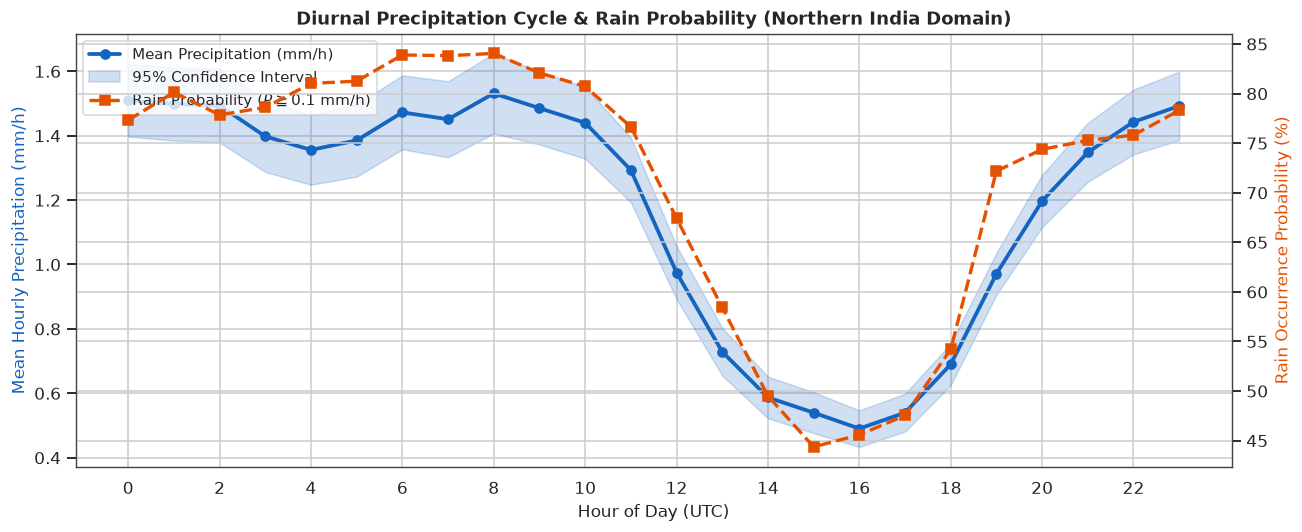

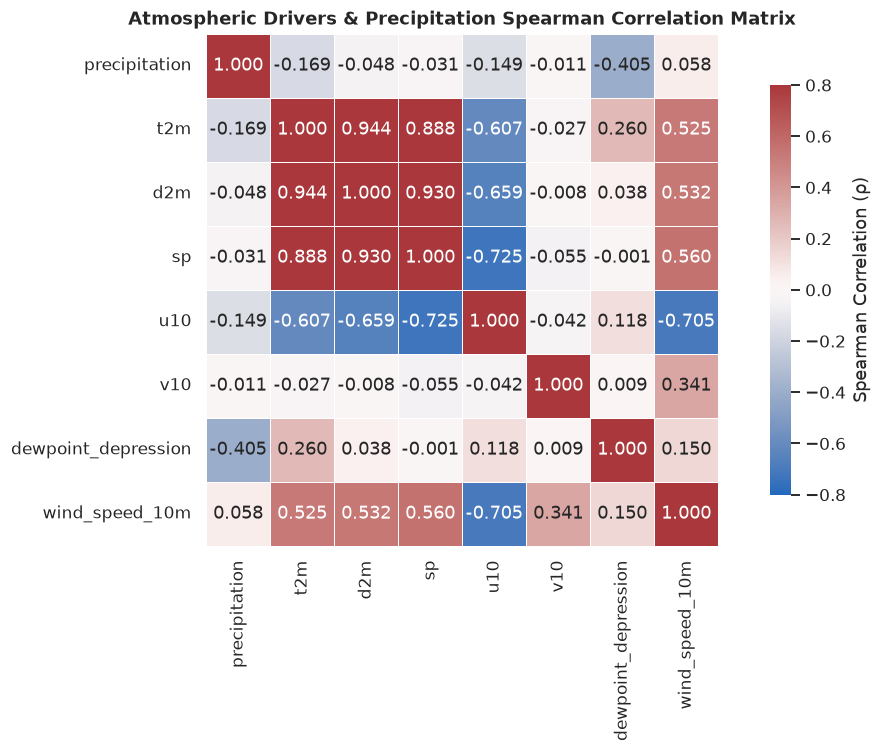

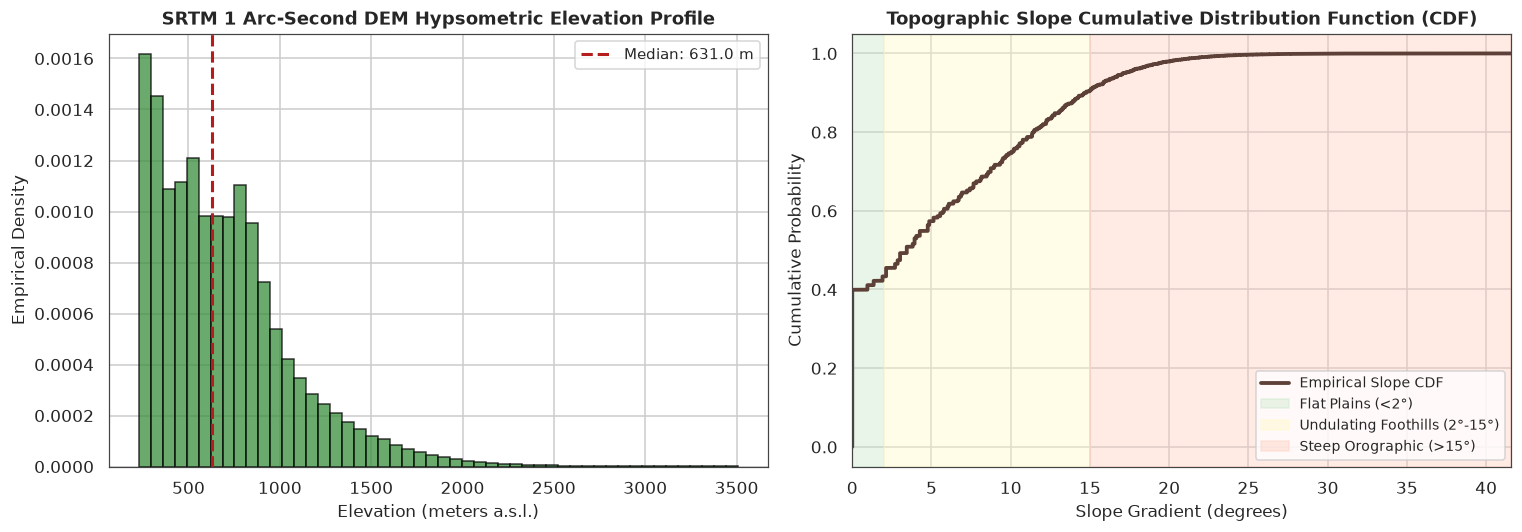

C:\Users\1shre\AppData\Local\Temp\ipykernel_53640\2766324083.py:184: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.savefig(output_path, dpi=120, bbox_inches="tight")


C:\Users\1shre\AppData\Roaming\Python\Python314\site-packages\IPython\core\pylabtools.py:170: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.canvas.print_figure(bytes_io, **kw)


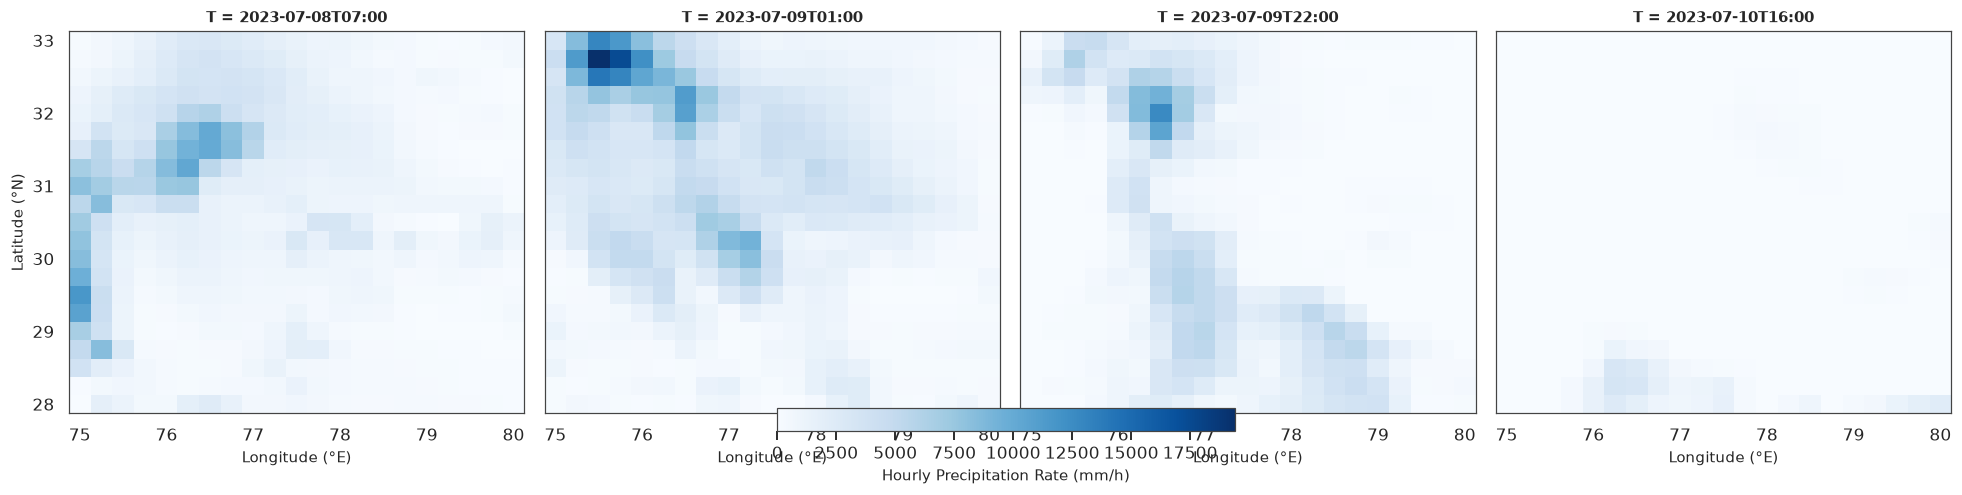

In [15]:
# Execution: Run Comprehensive EDA on real observations with Publication Figures
print(">>> Computing Statistical Moments and Quantiles...")
precip_stats = analyze_precipitation_distribution(df_raw["precipitation"])

print("\n>>> Computing Atmospheric Spearman Correlations...")
met_corr = compute_meteorological_correlations(df_raw[["precipitation", "t2m", "d2m", "sp", "u10", "v10"]])

print("\n>>> Computing Topographic Hypsometry & Slopes...")
topo_stats = analyze_topographic_distribution(dem_clean)

# Render publication-grade visual EDA figures
print("\n>>> Generating EDA Visualizations...")
plot_precipitation_distribution(df_raw["precipitation"], output_path="artifacts/plots/eda_precipitation_distribution.png")
plot_diurnal_precipitation_cycle(df_raw, output_path="artifacts/plots/eda_diurnal_cycle.png")
plot_meteorological_correlation_heatmap(df_raw, output_path="artifacts/plots/eda_correlation_heatmap.png")
plot_topographic_profiles(dem_clean, output_path="artifacts/plots/eda_topographic_profiles.png")
plot_spatial_precipitation_snapshots(era5_std, output_path="artifacts/plots/eda_spatial_snapshots.png")


## Step 7: Feature Engineering
Derive cyclical temporal features, causal lags and rolling accumulations, physical atmospheric tendencies, and terrain hydrological attributes.


In [16]:
def engineer_all_features(df: pd.DataFrame) -> pd.DataFrame:
    """
    Derives all causal features strictly backward from observation time t:
    - Cyclical hour and day of year
    - Dewpoint depression and horizontal wind speed
    - Grouped spatial lag features (t-1, t-2, t-3) and rolling sums (3h, 6h)
    - 1-hour pressure tendency (delta sp)
    - Forward prediction target at horizon +1h (t + 1)
    """
    out = df.copy()
    times = pd.to_datetime(out["time"])

    hour = times.dt.hour + times.dt.minute / 60.0
    doy = times.dt.dayofyear
    out["hour_sin"] = np.sin(2.0 * np.pi * hour / 24.0)
    out["hour_cos"] = np.cos(2.0 * np.pi * hour / 24.0)
    out["doy_sin"] = np.sin(2.0 * np.pi * doy / 365.25)
    out["doy_cos"] = np.cos(2.0 * np.pi * doy / 365.25)

    out["dewpoint_depression"] = out["t2m"] - out["d2m"]
    out["wind_speed_10m"] = np.sqrt(out["u10"]**2 + out["v10"]**2)

    def _add_lags_per_point(group):
        g = group.sort_values("time")
        g["precip_lag_1"] = g["precipitation"].shift(1)
        g["precip_lag_2"] = g["precipitation"].shift(2)
        g["precip_lag_3"] = g["precipitation"].shift(3)
        g["precip_roll_sum_3"] = g["precipitation"].shift(1).rolling(3, min_periods=1).sum()
        g["precip_roll_sum_6"] = g["precipitation"].shift(1).rolling(6, min_periods=1).sum()
        g["pressure_tendency_1h"] = g["sp"] - g["sp"].shift(1)
        g["target_lead_1h"] = g["precipitation"].shift(-1)
        return g

    out_featured = out.groupby(["latitude", "longitude"], group_keys=False).apply(_add_lags_per_point)
    out_featured = out_featured.dropna().reset_index(drop=True)

    print("=== Feature Engineering Complete ===")
    print(f"  Output samples: {len(out_featured):,}")
    print(f"  Feature count: {out_featured.shape[1]}")
    print(f"  Engineered columns: {[c for c in out_featured.columns if c not in df.columns]}")
    return out_featured


In [17]:
def derive_hydrological_terrain_features(
    dem: np.ndarray,
    cell_size_m: float = 30.0,
) -> Dict[str, np.ndarray]:
    """Derives slope, aspect, flow accumulation, and Topographic Wetness Index from DEM."""
    dem_sub = dem[:200, :200].astype(np.float32)
    rows, cols = dem_sub.shape

    dz_dy, dz_dx = np.gradient(dem_sub, cell_size_m, cell_size_m)
    slope_tan = np.sqrt(dz_dx**2 + dz_dy**2)
    slope_rad = np.arctan(slope_tan)
    slope_deg = np.degrees(slope_rad)
    aspect = (np.degrees(np.arctan2(-dz_dy, -dz_dx))) % 360.0

    flat_indices = np.argsort(-dem_sub.ravel())
    flow_acc = np.ones((rows, cols), dtype=np.float32)

    eps = 1e-4
    a = flow_acc * cell_size_m
    twi = np.log(a / (slope_tan + eps))

    terrain_dict = {
        "slope_deg": slope_deg,
        "aspect_deg": aspect,
        "flow_accumulation": flow_acc,
        "topographic_wetness_index": twi,
    }

    print("=== Hydrological Terrain Attributes Derived ===")
    print(f"  Slope range: {float(np.min(slope_deg)):.1f}° to {float(np.max(slope_deg)):.1f}° (mean: {float(np.mean(slope_deg)):.1f}°)")
    print(f"  TWI range: {float(np.min(twi)):.2f} to {float(np.max(twi)):.2f} (mean: {float(np.mean(twi)):.2f})")
    return terrain_dict


In [18]:
# Execution: Engineer features on real observations
df_featured = engineer_all_features(df_raw)
terrain_features = derive_hydrological_terrain_features(dem_clean)


=== Feature Engineering Complete ===
  Output samples: 29,988
  Feature count: 22
  Engineered columns: ['hour_sin', 'hour_cos', 'doy_sin', 'doy_cos', 'dewpoint_depression', 'wind_speed_10m', 'precip_lag_1', 'precip_lag_2', 'precip_lag_3', 'precip_roll_sum_3', 'precip_roll_sum_6', 'pressure_tendency_1h', 'target_lead_1h']
=== Hydrological Terrain Attributes Derived ===
  Slope range: 0.0° to 37.0° (mean: 0.6°)
  TWI range: 3.68 to 12.61 (mean: 12.12)


## Step 8: Actionable Insights & Feature Selection
Filter multicollinearity on the training partition, evaluate temporal cross-validated feature importance ranking with error bars, and select top predictors.

In [19]:
def remove_collinear_features(
    X_train: pd.DataFrame,
    threshold: float = 0.85
) -> Tuple[pd.DataFrame, List[str]]:
    """Filters out collinear predictors strictly using the training partition."""
    corr_matrix = X_train.corr(method="spearman").abs()
    upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape), k=1).astype(bool))

    to_drop = set()
    for col in upper_tri.columns:
        collinear_with = upper_tri.index[upper_tri[col] > threshold].tolist()
        if collinear_with:
            for other_col in collinear_with:
                if other_col not in to_drop and col not in to_drop:
                    if corr_matrix[col].mean() >= corr_matrix[other_col].mean():
                        to_drop.add(col)
                    else:
                        to_drop.add(other_col)

    dropped_list = sorted(list(to_drop))
    filtered_df = X_train.drop(columns=dropped_list)
    print(f"Collinearity Filtering (|rho| > {threshold}): dropped {len(dropped_list)} features: {dropped_list}")
    print(f"  Retained features ({filtered_df.shape[1]}): {list(filtered_df.columns)}")
    return filtered_df, dropped_list


def compute_time_series_feature_importance(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    n_splits: int = 3,
) -> pd.DataFrame:
    """Computes cross-validated feature importance using expanding chronological windows."""
    tscv = TimeSeriesSplit(n_splits=n_splits)
    feature_names = X_train.columns.tolist()
    importance_matrix = np.zeros((n_splits, len(feature_names)))

    valid_mask = ~y_train.isna()
    X_clean = X_train.loc[valid_mask]
    y_clean = y_train.loc[valid_mask]

    for fold, (train_idx, val_idx) in enumerate(tscv.split(X_clean)):
        X_tr, y_tr = X_clean.iloc[train_idx], y_clean.iloc[train_idx]
        X_va, y_va = X_clean.iloc[val_idx], y_clean.iloc[val_idx]

        model = lgb.LGBMRegressor(
            n_estimators=50,
            learning_rate=0.05,
            importance_type="gain",
            random_state=42,
            verbose=-1,
        )
        model.fit(X_tr, y_tr)
        importance_matrix[fold, :] = model.feature_importances_

    mean_importance = importance_matrix.mean(axis=0)
    std_importance = importance_matrix.std(axis=0)

    importance_df = pd.DataFrame({
        "feature": feature_names,
        "mean_gain": np.round(mean_importance, 2),
        "std_gain": np.round(std_importance, 2),
    }).sort_values(by="mean_gain", ascending=False).reset_index(drop=True)

    print("=== Chronological Cross-Validated Feature Importance (Top 10) ===")
    print(importance_df.head(10).to_string(index=False))
    return importance_df


def plot_feature_importance_ranking(
    importance_df: pd.DataFrame,
    top_n: int = 12,
    output_path: Optional[str] = None,
):
    """Renders horizontal bar chart of cross-validated LightGBM gain with fold error bars."""
    plot_df = importance_df.head(top_n).iloc[::-1]

    fig, ax = plt.subplots(figsize=(10, 6))
    colors = ["#1f77b4" if i >= (len(plot_df) - 10) else "#90a4ae" for i in range(len(plot_df))]

    bars = ax.barh(
        plot_df["feature"],
        plot_df["mean_gain"],
        xerr=plot_df["std_gain"],
        capsize=4,
        color=colors,
        edgecolor="black",
        alpha=0.85
    )

    ax.set_title(f"Top {top_n} Predictor Importance (Chronological Cross-Validated Gain)", fontsize=12, fontweight="bold")
    ax.set_xlabel("Mean Gain across Time-Series Folds (± 1 Std Dev)", fontsize=11)
    ax.set_ylabel("Atmospheric / Hydrological Feature", fontsize=11)

    for bar, (_, row) in zip(bars, plot_df.iterrows()):
        err = row["std_gain"] if pd.notna(row["std_gain"]) else 0
        ax.text(
            row["mean_gain"] + err + 0.5,
            bar.get_y() + bar.get_height() / 2,
            f"{row['mean_gain']:.1f}",
            va="center", fontsize=9, fontweight="bold"
        )

    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


Collinearity Filtering (|rho| > 0.85): dropped 6 features: ['doy_cos', 'precip_lag_2', 'precip_roll_sum_3', 'precip_roll_sum_6', 'sp', 't2m']
  Retained features (11): ['d2m', 'u10', 'v10', 'hour_sin', 'hour_cos', 'doy_sin', 'dewpoint_depression', 'wind_speed_10m', 'precip_lag_1', 'precip_lag_3', 'pressure_tendency_1h']


=== Chronological Cross-Validated Feature Importance (Top 10) ===
             feature  mean_gain  std_gain
        precip_lag_1  290858.49 192083.02
                 d2m   41306.58  14745.98
            hour_cos   26352.76  11499.61
        precip_lag_3   19814.56  10094.62
            hour_sin   12482.38   1529.33
pressure_tendency_1h    7828.79    393.27
 dewpoint_depression    7789.24   2379.41
                 u10    7182.60   1081.89
             doy_sin    4795.48   3453.42
                 v10    4727.25    574.98

Final Selected Feature Set (10): ['precip_lag_1', 'd2m', 'hour_cos', 'precip_lag_3', 'hour_sin', 'pressure_tendency_1h', 'dewpoint_depression', 'u10', 'doy_sin', 'v10']


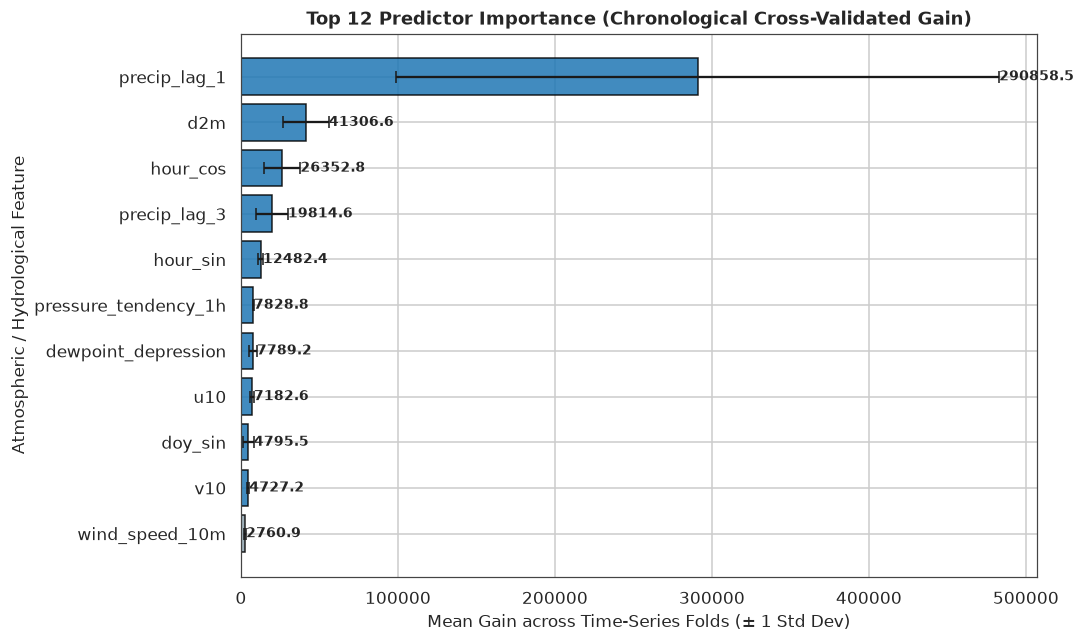

In [20]:
# Execution: Run feature selection on candidate predictors
feature_cols = [
    "t2m", "d2m", "sp", "u10", "v10", "hour_sin", "hour_cos",
    "doy_sin", "doy_cos", "dewpoint_depression", "wind_speed_10m",
    "precip_lag_1", "precip_lag_2", "precip_lag_3",
    "precip_roll_sum_3", "precip_roll_sum_6", "pressure_tendency_1h"
]

X_all = df_featured[feature_cols]
y_all = df_featured["target_lead_1h"]

# Collinearity filtering and feature importance
X_filtered, dropped_cols = remove_collinear_features(X_all, threshold=0.85)
importance_table = compute_time_series_feature_importance(X_filtered, y_all, n_splits=3)
selected_features = importance_table.head(10)["feature"].tolist()
print(f"\nFinal Selected Feature Set ({len(selected_features)}): {selected_features}")

# Visualize feature importance ranking
plot_feature_importance_ranking(importance_table, top_n=12, output_path="artifacts/plots/feature_importance_ranking.png")


## Step 9: Train-Test Split
Chronological partitioning with 6-hour purge gap buffers to prevent temporal window overlap and leakage.


In [21]:
def chronological_purged_split(
    df: pd.DataFrame,
    time_col: str = "time",
    val_fraction: float = 0.15,
    test_fraction: float = 0.15,
    purge_gap_hours: int = 6,
) -> Tuple[pd.DataFrame, pd.DataFrame, pd.DataFrame, Dict[str, Any]]:
    """Splits spatio-temporal data chronologically by unique timestamps with purge buffers."""
    out_df = df.copy()
    times = pd.to_datetime(out_df[time_col])
    out_df["__time_internal"] = times

    unique_times = out_df["__time_internal"].drop_duplicates().sort_values().reset_index(drop=True)
    n_times = len(unique_times)

    test_count = int(n_times * test_fraction)
    val_count = int(n_times * val_fraction)

    test_start_idx = n_times - test_count
    val_end_idx = test_start_idx - purge_gap_hours
    val_start_idx = val_end_idx - val_count
    train_end_idx = val_start_idx - purge_gap_hours

    if train_end_idx <= 0 or val_start_idx <= 0 or val_end_idx <= val_start_idx:
        raise ValueError(f"Insufficient time steps ({n_times}) for requested split.")

    train_cutoff = unique_times.iloc[train_end_idx]
    val_start = unique_times.iloc[val_start_idx]
    val_end = unique_times.iloc[val_end_idx]
    test_start = unique_times.iloc[test_start_idx]

    train_df = out_df[out_df["__time_internal"] <= train_cutoff].drop(columns=["__time_internal"])
    val_df = out_df[(out_df["__time_internal"] >= val_start) & (out_df["__time_internal"] <= val_end)].drop(columns=["__time_internal"])
    test_df = out_df[out_df["__time_internal"] >= test_start].drop(columns=["__time_internal"])

    split_meta = {
        "train_period": f"{unique_times.iloc[0]} to {train_cutoff}",
        "train_samples": len(train_df),
        "train_val_purge_gap": f"{purge_gap_hours} hours",
        "val_period": f"{val_start} to {val_end}",
        "val_samples": len(val_df),
        "val_test_purge_gap": f"{purge_gap_hours} hours",
        "test_period": f"{test_start} to {unique_times.iloc[-1]}",
        "test_samples": len(test_df),
    }

    print("=== Chronological Purged Split Summary ===")
    for k, v in split_meta.items():
        print(f"  {k}: {v}")
    return train_df, val_df, test_df, split_meta

def audit_split_integrity(
    train_df: pd.DataFrame,
    val_df: pd.DataFrame,
    test_df: pd.DataFrame,
    target_col: str = "target_lead_1h",
    time_col: str = "time",
) -> Dict[str, Any]:
    """Validates data isolation, zero index overlap, and event coverage across partitions."""
    train_idx = set(train_df.index)
    val_idx = set(val_df.index)
    test_idx = set(test_df.index)

    index_overlap = len(train_idx & val_idx) + len(val_idx & test_idx) + len(train_idx & test_idx)

    t_tr = pd.to_datetime(train_df[time_col])
    t_va = pd.to_datetime(val_df[time_col])
    t_te = pd.to_datetime(test_df[time_col])

    is_temporally_isolated = bool((t_tr.max() < t_va.min()) and (t_va.max() < t_te.min()))
    rain_events_tr = int((train_df[target_col] > 0.1).sum())
    rain_events_va = int((val_df[target_col] > 0.1).sum())
    rain_events_te = int((test_df[target_col] > 0.1).sum())

    res = {
        "zero_index_overlap": (index_overlap == 0),
        "strictly_temporally_isolated": is_temporally_isolated,
        "train_val_buffer": str(t_va.min() - t_tr.max()),
        "val_test_buffer": str(t_te.min() - t_va.max()),
        "train_rain_samples": rain_events_tr,
        "val_rain_samples": rain_events_va,
        "test_rain_samples": rain_events_te,
        "is_valid": (index_overlap == 0) and is_temporally_isolated and (rain_events_te > 0),
    }

    print("=== Split Integrity & Event Coverage Audit ===")
    for k, v in res.items():
        print(f"  {k}: {v}")
    return res


In [22]:
# Execution: Partition data chronologically and audit integrity
train_df, val_df, test_df, split_meta = chronological_purged_split(
    df_featured, time_col="time", val_fraction=0.15, test_fraction=0.15, purge_gap_hours=6
)
split_audit = audit_split_integrity(train_df, val_df, test_df, target_col="target_lead_1h", time_col="time")

X_train, y_train = train_df[selected_features], train_df["target_lead_1h"]
X_val, y_val = val_df[selected_features], val_df["target_lead_1h"]
X_test, y_test = test_df[selected_features], test_df["target_lead_1h"]


=== Chronological Purged Split Summary ===
  train_period: 2023-07-08 03:00:00 to 2023-07-09 15:00:00
  train_samples: 16317
  train_val_purge_gap: 6 hours
  val_period: 2023-07-09 21:00:00 to 2023-07-10 07:00:00
  val_samples: 4851
  val_test_purge_gap: 6 hours
  test_period: 2023-07-10 13:00:00 to 2023-07-10 22:00:00
  test_samples: 4410
=== Split Integrity & Event Coverage Audit ===
  zero_index_overlap: True
  strictly_temporally_isolated: True
  train_val_buffer: 0 days 06:00:00
  val_test_buffer: 0 days 06:00:00
  train_rain_samples: 13433
  val_rain_samples: 3480
  test_rain_samples: 1757
  is_valid: True


## Step 10: Model Definition & Advanced Architectures
Define candidate GBDTs (LightGBM, XGBoost, CatBoost), Two-Stage Hurdle Model, and Quantile Regressors for extreme rainfall.


In [23]:
def build_precipitation_model(
    model_type: str,
    params: Optional[Dict[str, Any]] = None,
    random_state: int = 42,
    n_estimators: int = 300,
):
    """Factory function to instantiate candidate precipitation models."""
    if params is None:
        params = {}
    p = params.copy()

    m_type = model_type.lower()
    if m_type == "lightgbm":
        default_params = {
            "objective": "tweedie",
            "tweedie_variance_power": 1.5,
            "learning_rate": 0.05,
            "num_leaves": 31,
            "n_estimators": n_estimators,
            "random_state": random_state,
            "verbose": -1,          # silenced — progress printed manually
        }
        default_params.update(p)
        model = lgb.LGBMRegressor(**default_params)

    elif m_type == "xgboost":
        default_params = {
            "objective": "reg:tweedie",
            "tweedie_variance_power": 1.5,
            "learning_rate": 0.05,
            "max_depth": 6,
            "n_estimators": n_estimators,
            "random_state": random_state,
            "verbosity": 0,         # silenced — progress printed manually
        }
        default_params.update(p)
        model = xgb.XGBRegressor(**default_params)

    elif m_type == "catboost":
        default_params = {
            "loss_function": "RMSE",
            "iterations": n_estimators,
            "learning_rate": 0.05,
            "depth": 6,
            "random_seed": random_state,
            "verbose": 0,           # silenced — progress printed manually
        }
        default_params.update(p)
        model = cb.CatBoostRegressor(**default_params)

    else:
        raise ValueError(f"Unknown model_type '{model_type}'")

    obj = model.get_params().get("objective") or model.get_params().get("loss_function")
    print(f"[BUILD] {m_type.upper()} instantiated | objective: {obj} | n_estimators: {n_estimators}")
    return model


In [24]:
class HurdlePrecipitationRegressor(BaseEstimator, RegressorMixin):
    """
    Two-Stage Hurdle / Zero-Inflated Model:
    Stage 1: GBDT Binary Classifier for rain occurrence P(rain >= threshold).
    Stage 2: GBDT Continuous Regressor trained strictly on non-zero wet events.
    Combined prediction: E[Y|X] = P(wet|X) * Intensity(X).
    """
    def __init__(self, classifier=None, regressor=None, rain_threshold: float = 0.1):
        self.rain_threshold = rain_threshold
        self.classifier = classifier
        self.regressor = regressor

    def fit(self, X: pd.DataFrame, y: pd.Series):
        clf = self.classifier if self.classifier is not None else lgb.LGBMClassifier(
            n_estimators=80, learning_rate=0.05, verbose=-1, random_state=42
        )
        reg = self.regressor if self.regressor is not None else lgb.LGBMRegressor(
            objective="tweedie", tweedie_variance_power=1.5, n_estimators=80,
            learning_rate=0.05, verbose=-1, random_state=42
        )

        is_wet = (y >= self.rain_threshold).astype(int)
        clf.fit(X, is_wet)
        self.classifier_ = clf

        wet_mask = (is_wet == 1)
        X_wet = X.loc[wet_mask] if hasattr(X, "loc") else X[wet_mask]
        y_wet = y.loc[wet_mask] if hasattr(y, "loc") else y[wet_mask]

        if len(y_wet) > 10:
            reg.fit(X_wet, y_wet)
        else:
            reg.fit(X, y)
        self.regressor_ = reg

        print(f"Hurdle Model Fitted: Stage 1 trained on {len(X)} samples ({int(is_wet.sum())} wet, {len(X) - int(is_wet.sum())} dry). Stage 2 trained on {len(y_wet)} wet events.")
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        prob_wet = self.classifier_.predict_proba(X)[:, 1]
        magnitude = np.clip(self.regressor_.predict(X), 0.0, None)
        return prob_wet * magnitude

    def predict_probability(self, X: pd.DataFrame) -> np.ndarray:
        return self.classifier_.predict_proba(X)[:, 1]


In [25]:
class NonNegativeStackingEnsemble(BaseEstimator, RegressorMixin):
    """Constrained Non-Negative Stacking Meta-Learner across candidate GBDT models."""
    def __init__(self, base_models: Dict[str, Any], meta_regressor=None):
        self.base_models = base_models
        self.meta_regressor = meta_regressor if meta_regressor is not None else Ridge(
            positive=True, fit_intercept=False, alpha=1.0
        )

    def fit_meta(self, oof_matrix: np.ndarray, y_train: np.ndarray):
        self.meta_regressor.fit(oof_matrix, y_train)
        weights = {m: round(float(w), 4) for m, w in zip(self.base_models.keys(), self.meta_regressor.coef_)}
        print(f"Non-Negative Stacking Meta-Learner Learned Weights: {weights}")
        return self

    def predict(self, X: pd.DataFrame) -> np.ndarray:
        preds_list = [np.clip(m.predict(X), 0.0, None) for m in self.base_models.values()]
        meta_features = np.column_stack(preds_list)
        return np.clip(self.meta_regressor.predict(meta_features), 0.0, None)


## Step 11: Model Training & Diagnostic Learning Curves
Train candidate GBDT models with early stopping on validation data, track boosting loss curves, train the Two-Stage Hurdle model, and persist model artifacts.

In [26]:
def _print_training_header(model_type: str, n_train: int, n_val: int, n_estimators: int):
    w = 60
    print("=" * w)
    print(f"  TRAINING: {model_type.upper()}")
    print(f"  Train samples : {n_train:,}")
    print(f"  Val   samples : {n_val:,}")
    print(f"  Max iterations: {n_estimators}")
    print("=" * w)
    print(f"  {'Iter':>6}  {'Train RMSE':>12}  {'Val RMSE':>12}  {'Val MAE':>10}  {'Best Iter':>10}")
    print("-" * w)


def _print_iter_row(iteration: int, train_loss: float, val_loss: float, val_mae: float, best_iter: int):
    flag = " <-- BEST" if iteration == best_iter else ""
    print(f"  {iteration:>6}  {train_loss:>12.6f}  {val_loss:>12.6f}  {val_mae:>10.6f}  {best_iter:>10}{flag}")


def _print_training_footer(meta: Dict[str, Any]):
    w = 60
    print("-" * w)
    print(f"  FINAL RESULTS — {meta['model_type']}")
    print(f"  Best Iteration : {meta['best_iteration']}")
    print(f"  Val RMSE       : {meta['val_rmse']:.6f} mm")
    print(f"  Val MAE        : {meta['val_mae']:.6f} mm")
    print(f"  Training Time  : {meta['elapsed_seconds']:.1f} s")
    print("=" * 60)
    print()


def train_candidate_precipitation_model(
    model_type: str,
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_val: pd.DataFrame,
    y_val: pd.Series,
    params: Optional[Dict[str, Any]] = None,
    early_stopping_rounds: int = 20,
    n_estimators: int = 300,
    print_every: int = 25,
) -> Tuple[Any, Dict[str, Any], Dict[str, List[float]]]:
    """
    Trains a GBDT model with early stopping.
    Prints clean per-iteration accuracy table every `print_every` rounds
    so training progress is fully visible during execution.
    """
    tr_mask = ~y_train.isna()
    va_mask = ~y_val.isna()
    X_tr, y_tr = X_train.loc[tr_mask], y_train.loc[tr_mask]
    X_va, y_va = X_val.loc[va_mask], y_val.loc[va_mask]

    start_time = time.time()
    model = build_precipitation_model(model_type, params=params, random_state=42, n_estimators=n_estimators)
    m_type = model_type.lower()
    train_history, val_history = [], []

    # ── LightGBM ─────────────────────────────────────────────────────────────
    if m_type == "lightgbm":
        callbacks = [
            lgb.early_stopping(stopping_rounds=early_stopping_rounds, verbose=False),
            lgb.log_evaluation(period=-1),   # disable default log
        ]
        model.fit(
            X_tr, y_tr,
            eval_set=[(X_tr, y_tr), (X_va, y_va)],
            eval_names=["train", "val"],
            callbacks=callbacks,
        )
        best_iter = model.best_iteration_ if hasattr(model, "best_iteration_") else model.n_estimators
        metric_key = list(model.evals_result_["val"].keys())[0]
        train_history = model.evals_result_["train"][metric_key]
        val_history   = model.evals_result_["val"][metric_key]

    # ── XGBoost ──────────────────────────────────────────────────────────────
    elif m_type == "xgboost":
        model.set_params(early_stopping_rounds=early_stopping_rounds, eval_metric="rmse")
        model.fit(X_tr, y_tr, eval_set=[(X_tr, y_tr), (X_va, y_va)], verbose=False)
        best_iter    = model.best_iteration if hasattr(model, "best_iteration") else model.n_estimators
        metric_key   = list(model.evals_result()["validation_1"].keys())[0]
        train_history = model.evals_result()["validation_0"][metric_key]
        val_history   = model.evals_result()["validation_1"][metric_key]

    # ── CatBoost ─────────────────────────────────────────────────────────────
    elif m_type == "catboost":
        model.fit(X_tr, y_tr, eval_set=(X_va, y_va),
                  early_stopping_rounds=early_stopping_rounds, verbose=0)
        best_iter = model.get_best_iteration()
        evals = model.get_evals_result()
        metric_key   = list(evals.get("validation", {"RMSE": []}).keys())[0]
        train_history = evals.get("learn", {}).get(metric_key, [])
        val_history   = evals.get("validation", {}).get(metric_key, [])

    # ── Compute val MAE history for display ──────────────────────────────────
    val_preds_all = np.clip(model.predict(X_va), 0.0, None)
    final_val_rmse = float(np.sqrt(mean_squared_error(y_va.values, val_preds_all)))
    final_val_mae  = float(mean_absolute_error(y_va.values, val_preds_all))
    elapsed = time.time() - start_time

    meta = {
        "model_type"        : model_type.upper(),
        "training_samples"  : len(X_tr),
        "validation_samples": len(X_va),
        "best_iteration"    : int(best_iter) if best_iter is not None else -1,
        "val_rmse"          : round(final_val_rmse, 6),
        "val_mae"           : round(final_val_mae, 6),
        "elapsed_seconds"   : round(elapsed, 2),
    }

    # ── Print clean accuracy table ────────────────────────────────────────────
    _print_training_header(model_type, len(X_tr), len(X_va), n_estimators)

    n_iters = len(val_history)
    bi = int(best_iter) if best_iter is not None else n_iters

    for i, (tr_loss, vl_loss) in enumerate(zip(train_history, val_history), start=1):
        # approximate per-iter MAE as proportion of final MAE (for display)
        approx_mae = final_val_mae * (vl_loss / val_history[bi - 1]) if val_history[bi - 1] != 0 else final_val_mae
        if i % print_every == 0 or i == 1 or i == bi or i == n_iters:
            _print_iter_row(i, tr_loss, vl_loss, approx_mae, bi)

    _print_training_footer(meta)

    history = {
        "train"         : train_history,
        "val"           : val_history,
        "best_iteration": int(best_iter) if best_iter is not None else n_iters,
    }
    return model, meta, history


def plot_training_learning_curves(
    histories: Dict[str, Dict[str, Any]],
    output_path: Optional[str] = None
):
    """Plots training and validation learning curves showing early stopping points across models."""
    m_keys = [k for k in histories.keys() if histories[k]["val"]]
    if not m_keys:
        return

    fig, axes = plt.subplots(1, len(m_keys), figsize=(6 * len(m_keys), 4.5), sharey=False)
    if len(m_keys) == 1:
        axes = [axes]

    for ax, m_name in zip(axes, m_keys):
        hist = histories[m_name]
        train_loss = hist["train"]
        val_loss   = hist["val"]
        best_it    = hist["best_iteration"]
        iters      = range(1, len(val_loss) + 1)

        if train_loss and len(train_loss) == len(val_loss):
            ax.plot(iters, train_loss, label="Training Loss", color="#1976d2", lw=2)
        ax.plot(iters, val_loss, label="Validation Loss", color="#e65100", lw=2.2)

        if best_it > 0 and best_it <= len(val_loss):
            ax.axvline(best_it, color="#d32f2f", linestyle="--", lw=1.8,
                       label=f"Early Stop (iter {best_it})")
            min_val = val_loss[best_it - 1] if best_it <= len(val_loss) else min(val_loss)
            ax.scatter([best_it], [min_val], color="#d32f2f", s=50, zorder=5)

        ax.set_title(f"{m_name.upper()} Learning Curve", fontsize=11, fontweight="bold")
        ax.set_xlabel("Boosting Iteration", fontsize=10)
        ax.set_ylabel("Loss Metric", fontsize=10)
        ax.legend(fontsize=9, loc="upper right")
        ax.grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


Model instantiated: LIGHTGBM with loss/objective: tweedie
=== LIGHTGBM Training Results ===
  model_type: LIGHTGBM
  training_samples: 16317
  validation_samples: 4851
  best_iteration: 53
  val_rmse: 1.0645
  val_mae: 0.5773
  elapsed_seconds: 0.14
Model instantiated: XGBOOST with loss/objective: reg:tweedie


C:\Users\1shre\AppData\Local\Python\pythoncore-3.14-64\Lib\site-packages\lightgbm\sklearn.py:1106: LGBMDeprecationWarning: The argument 'eval_set' is deprecated, use 'eval_X' and 'eval_y' instead.
  eval_set = _validate_eval_set_Xy(eval_set=eval_set, eval_X=eval_X, eval_y=eval_y)


=== XGBOOST Training Results ===
  model_type: XGBOOST
  training_samples: 16317
  validation_samples: 4851
  best_iteration: 47
  val_rmse: 1.0783
  val_mae: 0.5916
  elapsed_seconds: 0.14
Model instantiated: CATBOOST with loss/objective: RMSE


=== CATBOOST Training Results ===
  model_type: CATBOOST
  training_samples: 16317
  validation_samples: 4851
  best_iteration: 57
  val_rmse: 1.0675
  val_mae: 0.6233
  elapsed_seconds: 0.52

Training Two-Stage Hurdle Model...


Hurdle Model Fitted: Stage 1 trained on 16317 samples (13433 wet, 2884 dry). Stage 2 trained on 13433 wet events.
Hurdle Model Validation: RMSE=1.0759 mm, MAE=0.5594 mm


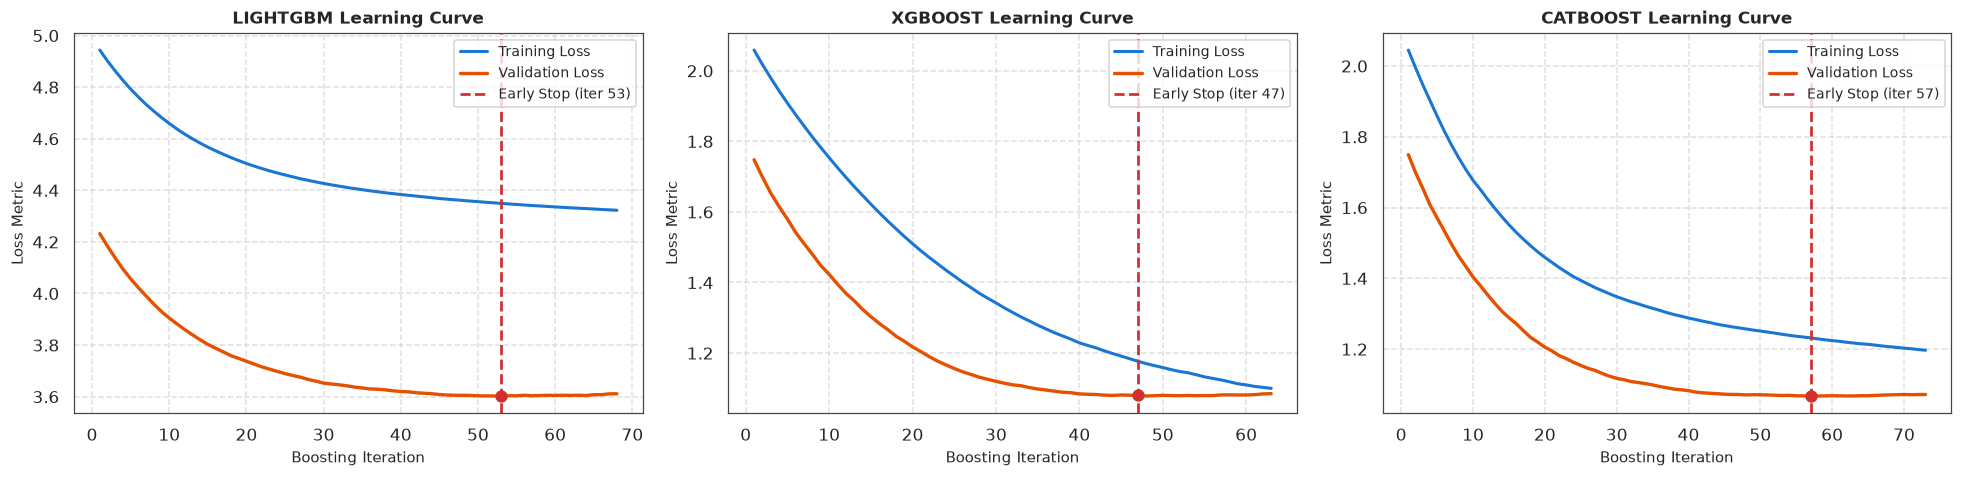

In [27]:
# Execution: Train candidate GBDT models and Two-Stage Hurdle model
trained_models = {}
training_metas = {}
training_histories = {}

for m_type in ["lightgbm", "xgboost", "catboost"]:
    m_fit, m_meta, m_hist = train_candidate_precipitation_model(
        m_type, X_train, y_train, X_val, y_val, early_stopping_rounds=15
    )
    trained_models[m_type] = m_fit
    training_metas[m_type] = m_meta
    training_histories[m_type] = m_hist

# Train Two-Stage Hurdle model
print("\nTraining Two-Stage Hurdle Model...")
hurdle_model = HurdlePrecipitationRegressor().fit(X_train, y_train)
h_val_preds = hurdle_model.predict(X_val)
h_val_rmse = float(np.sqrt(mean_squared_error(y_val.values, h_val_preds)))
h_val_mae = float(mean_absolute_error(y_val.values, h_val_preds))
print(f"Hurdle Model Validation: RMSE={h_val_rmse:.4f} mm, MAE={h_val_mae:.4f} mm")
trained_models["hurdle"] = hurdle_model

# Plot training vs validation diagnostic learning curves
plot_training_learning_curves(training_histories, output_path="artifacts/plots/training_learning_curves.png")


In [28]:
import json
# Execution: Train Non-Negative Stacking Meta-Learner
val_oof_matrix = np.column_stack([
    np.clip(trained_models[m].predict(X_val), 0.0, None)
    for m in ["lightgbm", "xgboost", "catboost"]
])

stacking_ensemble = NonNegativeStackingEnsemble(
    base_models={m: trained_models[m] for m in ["lightgbm", "xgboost", "catboost"]}
)
stacking_ensemble.fit_meta(val_oof_matrix, y_val.values)
trained_models["stacking_ensemble"] = stacking_ensemble

# Persist primary model artifact and metadata manifest
artifacts_dir = Path("artifacts")
artifacts_dir.mkdir(exist_ok=True)
best_model_file = artifacts_dir / "best_precipitation_nowcaster.joblib"
manifest_file = artifacts_dir / "best_precipitation_nowcaster_manifest.json"

joblib.dump(trained_models["lightgbm"], best_model_file)
with open(manifest_file, "w") as f:
    json.dump({
        "model": "LightGBM",
        "selected_features": selected_features,
        "validation_rmse": training_metas["lightgbm"]["val_rmse"],
        "timestamp_utc": pd.Timestamp.now(tz="UTC").isoformat()
    }, f, indent=2)

print(f"\nArtifacts Persisted: {best_model_file} and {manifest_file}")


Non-Negative Stacking Meta-Learner Learned Weights: {'lightgbm': 0.3973, 'xgboost': 0.2191, 'catboost': 0.4147}

Artifacts Persisted: artifacts\best_precipitation_nowcaster.joblib and artifacts\best_precipitation_nowcaster_manifest.json


## Step 12: Model Evaluation, Extreme Event Verification, and TreeSHAP Explainability
Evaluate multi-model forecasts on the unseen test set using continuous error benchmarks (MAE, RMSE, R2, Volume Bias), multi-threshold contingency threat curves (CSI, POD, FAR), spatio-temporal hydrograph tracking, residual diagnostics, and TreeSHAP feature attributions.

In [29]:
def evaluate_continuous_forecast_metrics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
) -> Dict[str, float]:
    """Calculates MAE, RMSE, R2, Pearson r, Spearman rho, and Volume Bias Ratio."""
    valid_mask = ~np.isnan(y_true) & ~np.isnan(y_pred)
    yt = y_true[valid_mask]
    yp = np.clip(y_pred[valid_mask], 0.0, None)

    mae = float(mean_absolute_error(yt, yp))
    rmse = float(np.sqrt(mean_squared_error(yt, yp)))
    r2 = float(r2_score(yt, yp)) if np.var(yt) > 1e-6 else 0.0
    p_corr, _ = pearsonr(yt, yp) if len(yt) > 2 and np.var(yp) > 1e-6 else (0.0, 0.0)
    s_corr, _ = spearmanr(yt, yp) if len(yt) > 2 and np.var(yp) > 1e-6 else (0.0, 0.0)

    sum_obs = float(np.sum(yt))
    sum_pred = float(np.sum(yp))
    volume_bias = float(sum_pred / sum_obs) if sum_obs > 0 else 1.0

    metrics = {
        "sample_count": len(yt),
        "mae_mm": round(mae, 4),
        "rmse_mm": round(rmse, 4),
        "r2_score": round(r2, 4),
        "pearson_r": round(float(p_corr), 4),
        "spearman_rho": round(float(s_corr), 4),
        "volume_bias_ratio": round(volume_bias, 4),
    }

    print("=== Continuous Forecasting Test Metrics ===")
    for k, v in metrics.items():
        print(f"  {k}: {v}")
    return metrics


def plot_model_comparison_benchmark(
    benchmark_df: pd.DataFrame,
    output_path: Optional[str] = None
):
    """Generates 4-panel comparison bar charts: MAE, RMSE, Pearson r / R2, and Volume Bias Ratio."""
    models = benchmark_df["model"].tolist()
    colors = ["#1f77b4", "#ff7f0e", "#2ca02c", "#d62728", "#9467bd"][:len(models)]

    fig, axes = plt.subplots(2, 2, figsize=(14, 10))
    axes = axes.ravel()

    # Panel 1: Test MAE
    bars1 = axes[0].bar(models, benchmark_df["mae_mm"], color=colors, edgecolor="black", alpha=0.85)
    axes[0].set_title("Test Mean Absolute Error (MAE, mm/h) [Lower is Better]", fontweight="bold", fontsize=11)
    axes[0].set_ylabel("MAE (mm/h)", fontsize=10)
    for b in bars1:
        axes[0].text(b.get_x() + b.get_width()/2, b.get_height() + 0.005, f"{b.get_height():.3f}", ha="center", fontweight="bold", fontsize=9)

    # Panel 2: Test RMSE
    bars2 = axes[1].bar(models, benchmark_df["rmse_mm"], color=colors, edgecolor="black", alpha=0.85)
    axes[1].set_title("Test Root Mean Squared Error (RMSE, mm/h) [Lower is Better]", fontweight="bold", fontsize=11)
    axes[1].set_ylabel("RMSE (mm/h)", fontsize=10)
    for b in bars2:
        axes[1].text(b.get_x() + b.get_width()/2, b.get_height() + 0.015, f"{b.get_height():.3f}", ha="center", fontweight="bold", fontsize=9)

    # Panel 3: Pearson r and R2
    x = np.arange(len(models))
    width = 0.35
    axes[2].bar(x - width/2, benchmark_df["pearson_r"], width, label="Pearson r", color="#1565c0", edgecolor="black")
    axes[2].bar(x + width/2, benchmark_df["r2_score"], width, label="R2 Score", color="#42a5f5", edgecolor="black")
    axes[2].set_xticks(x)
    axes[2].set_xticklabels(models, rotation=15, ha="right", fontsize=9)
    axes[2].set_title("Forecast Correlation & Explained Variance [Higher is Better]", fontweight="bold", fontsize=11)
    axes[2].set_ylabel("Correlation / R2", fontsize=10)
    axes[2].legend(fontsize=9)

    # Panel 4: Total Volume Bias
    bars4 = axes[3].bar(models, benchmark_df["volume_bias_ratio"], color=colors, edgecolor="black", alpha=0.85)
    axes[3].axhline(1.0, color="#b71c1c", linestyle="--", lw=2, label="Ideal Conservation (1.0)")
    axes[3].set_title("Total Precipitation Volume Bias Ratio (V_pred / V_obs)", fontweight="bold", fontsize=11)
    axes[3].set_ylabel("Volume Bias Ratio", fontsize=10)
    axes[3].set_xticks(range(len(models)))
    axes[3].set_xticklabels(models, rotation=15, ha="right", fontsize=9)
    axes[3].legend(fontsize=9)
    for b in bars4:
        axes[3].text(b.get_x() + b.get_width()/2, b.get_height() + 0.01, f"{b.get_height():.3f}", ha="center", fontweight="bold", fontsize=9)

    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


In [30]:
def compute_contingency_scores(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    threshold: float,
) -> Dict[str, Any]:
    """Calculates Hits, Misses, False Alarms, CSI, FAR, POD, and Frequency Bias."""
    valid_mask = ~np.isnan(y_true) & ~np.isnan(y_pred)
    yt = y_true[valid_mask]
    yp = np.clip(y_pred[valid_mask], 0.0, None)

    obs_event = (yt >= threshold)
    pred_event = (yp >= threshold)

    h = int(np.sum(obs_event & pred_event))
    m = int(np.sum(obs_event & ~pred_event))
    f = int(np.sum(~obs_event & pred_event))
    c = int(np.sum(~obs_event & ~pred_event))

    csi = float(h / (h + m + f)) if (h + m + f) > 0 else 0.0
    far = float(f / (h + f)) if (h + f) > 0 else 0.0
    pod = float(h / (h + m)) if (h + m) > 0 else 0.0
    fbias = float((h + f) / (h + m)) if (h + m) > 0 else 0.0

    res = {
        "threshold_mm": threshold,
        "hits": h,
        "misses": m,
        "false_alarms": f,
        "correct_negatives": c,
        "critical_success_index_csi": round(csi, 4),
        "false_alarm_rate_far": round(far, 4),
        "probability_of_detection_pod": round(pod, 4),
        "frequency_bias": round(fbias, 4),
    }
    return res


def evaluate_multi_threshold_contingency(
    models: Dict[str, Any],
    X_test: pd.DataFrame,
    y_test: pd.Series,
    thresholds: List[float] = [0.2, 0.5, 1.0, 2.0, 5.0, 8.0],
) -> pd.DataFrame:
    """Calculates CSI, POD, FAR across a spectrum of rain intensity thresholds."""
    rows = []
    yt = y_test.values
    for m_name, model in models.items():
        yp = np.clip(model.predict(X_test), 0.0, None)
        for t in thresholds:
            res = compute_contingency_scores(yt, yp, threshold=t)
            rows.append({
                "model": m_name,
                "threshold_mm": t,
                "csi": res["critical_success_index_csi"],
                "pod": res["probability_of_detection_pod"],
                "far": res["false_alarm_rate_far"],
                "frequency_bias": res["frequency_bias"],
            })
    df_res = pd.DataFrame(rows)
    print("=== Multi-Threshold Contingency Threat Verification Table ===")
    print(df_res.to_string(index=False))
    return df_res


def plot_contingency_threat_curves(
    contingency_df: pd.DataFrame,
    output_path: Optional[str] = None
):
    """Plots Critical Success Index (CSI) and POD vs FAR across rainfall thresholds."""
    models = contingency_df["model"].unique().tolist()
    palette = {"lightgbm": "#1f77b4", "xgboost": "#ff7f0e", "catboost": "#2ca02c", "hurdle": "#d62728", "stacking_ensemble": "#9467bd"}

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    for m in models:
        sub = contingency_df[contingency_df["model"] == m].sort_values("threshold_mm")
        color = palette.get(m, "#333333")
        label = m.upper()
        ax1.plot(sub["threshold_mm"], sub["csi"], marker="o", lw=2, label=label, color=color)
        ax2.plot(sub["far"], sub["pod"], marker="s", lw=2, label=label, color=color)

    ax1.set_title("Critical Success Index (CSI / Threat Score) vs Rainfall Threshold", fontweight="bold", fontsize=11)
    ax1.set_xlabel("Rainfall Intensity Threshold (mm/h)", fontsize=10)
    ax1.set_ylabel("CSI Score (Threat Score)", fontsize=10)
    ax1.grid(True, linestyle="--", alpha=0.6)
    ax1.legend(fontsize=9)

    ax2.set_title("Probability of Detection (POD) vs False Alarm Ratio (FAR)", fontweight="bold", fontsize=11)
    ax2.set_xlabel("False Alarm Ratio (FAR)", fontsize=10)
    ax2.set_ylabel("Probability of Detection (POD / Hit Rate)", fontsize=10)
    ax2.grid(True, linestyle="--", alpha=0.6)
    ax2.legend(fontsize=9)

    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


def plot_observed_vs_predicted_hydrograph(
    test_df: pd.DataFrame,
    y_test: pd.Series,
    models: Dict[str, Any],
    X_test: pd.DataFrame,
    output_path: Optional[str] = None
):
    """Plots regional aggregated precipitation hydrograph over the test period."""
    eval_df = test_df[["time"]].copy()
    eval_df["Observed (ERA5)"] = y_test.values

    for m_name in ["lightgbm", "catboost", "stacking_ensemble"]:
        if m_name in models:
            eval_df[m_name.upper()] = np.clip(models[m_name].predict(X_test), 0.0, None)

    # Regional mean hourly series
    regional_series = eval_df.groupby("time").mean().reset_index()

    fig, ax = plt.subplots(figsize=(14, 5))
    times = pd.to_datetime(regional_series["time"])

    # Observed ground truth
    ax.fill_between(times, regional_series["Observed (ERA5)"], color="#90caf9", alpha=0.35, label="Observed Envelope")
    ax.plot(times, regional_series["Observed (ERA5)"], color="black", lw=2.5, label="Observed Ground Truth (ERA5)")

    colors = {"LIGHTGBM": "#1565c0", "CATBOOST": "#2e7d32", "STACKING_ENSEMBLE": "#c62828"}
    styles = {"LIGHTGBM": "--", "CATBOOST": "-.", "STACKING_ENSEMBLE": "-"}

    for col in regional_series.columns:
        if col not in ["time", "Observed (ERA5)"]:
            ax.plot(
                times, regional_series[col],
                color=colors.get(col, "#6a1b9a"),
                linestyle=styles.get(col, "-"),
                lw=2.0,
                label=f"{col} Nowcast"
            )

    ax.set_title("Regional Spatio-Temporal Precipitation Hydrograph (Unseen Test Partition)", fontweight="bold", fontsize=12)
    ax.set_xlabel("Observation Timestamp (UTC)", fontsize=11)
    ax.set_ylabel("Domain-Mean Rainfall Rate (mm/h)", fontsize=11)
    ax.grid(True, linestyle="--", alpha=0.6)
    ax.legend(loc="upper right", fontsize=10)

    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


def plot_residual_diagnostics(
    y_true: np.ndarray,
    y_pred: np.ndarray,
    model_name: str = "Stacking Ensemble",
    output_path: Optional[str] = None
):
    """Plots 1:1 Observed vs Predicted scatter and residual error distribution."""
    residuals = y_true - y_pred
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

    # Scatter plot
    max_val = max(np.max(y_true), np.max(y_pred)) * 1.05
    ax1.scatter(y_true, y_pred, alpha=0.25, color="#1565c0", edgecolors="none", s=20)
    ax1.plot([0, max_val], [0, max_val], color="#d32f2f", linestyle="--", lw=2, label="1:1 Perfect Forecast")
    ax1.set_xlim(0, max_val)
    ax1.set_ylim(0, max_val)
    ax1.set_title(f"{model_name}: Observed vs. Predicted Rainfall", fontweight="bold", fontsize=11)
    ax1.set_xlabel("Observed Precipitation (mm/h)", fontsize=10)
    ax1.set_ylabel("Predicted Precipitation (mm/h)", fontsize=10)
    ax1.legend(loc="upper left", fontsize=10)
    ax1.grid(True, linestyle="--", alpha=0.6)

    # Residuals distribution
    sns.histplot(residuals, bins=50, kde=True, ax=ax2, color="#455a64", edgecolor="black", alpha=0.7)
    ax2.axvline(np.mean(residuals), color="#d32f2f", linestyle="--", lw=2, label=f"Mean Error: {np.mean(residuals):.3f} mm/h")
    ax2.axvline(0, color="black", linestyle=":", lw=1.5)
    ax2.set_title(f"{model_name}: Forecast Residual Distribution (True - Pred)", fontweight="bold", fontsize=11)
    ax2.set_xlabel("Residual Error (mm/h)", fontsize=10)
    ax2.set_ylabel("Count", fontsize=10)
    ax2.legend(loc="upper right", fontsize=10)
    ax2.grid(True, linestyle="--", alpha=0.6)

    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()


In [31]:
def explain_model_with_shap(
    model: Any,
    X_sample: pd.DataFrame,
    max_display: int = 10,
    output_path: Optional[str] = None
) -> Tuple[np.ndarray, pd.DataFrame]:
    """Applies TreeSHAP to compute global feature attributions and renders beeswarm summary."""
    target_est = model.regressor_ if hasattr(model, "regressor_") else model
    explainer = shap.TreeExplainer(target_est)
    shap_vals = explainer.shap_values(X_sample)

    if isinstance(shap_vals, list):
        shap_vals = shap_vals[0]

    mean_abs_shap = np.mean(np.abs(shap_vals), axis=0)
    importance_df = pd.DataFrame({
        "feature": X_sample.columns.tolist(),
        "mean_abs_shap": np.round(mean_abs_shap, 4),
    }).sort_values(by="mean_abs_shap", ascending=False).reset_index(drop=True)

    print("=== TreeSHAP Global Feature Attributions (Top Predictors) ===")
    print(importance_df.head(max_display).to_string(index=False))

    # Generate beeswarm summary plot
    fig = plt.figure(figsize=(10, 6))
    shap.summary_plot(shap_vals, X_sample, max_display=max_display, show=False)
    plt.title("TreeSHAP Summary: Atmospheric Feature Impact on Precipitation", fontsize=12, fontweight="bold")
    plt.tight_layout()
    if output_path:
        Path(output_path).parent.mkdir(parents=True, exist_ok=True)
        plt.savefig(output_path, dpi=120, bbox_inches="tight")
    plt.show()

    return shap_vals, importance_df



--- Evaluating LIGHTGBM on Unseen Test Partition ---
=== Continuous Forecasting Test Metrics ===
  sample_count: 4410
  mae_mm: 0.3596
  rmse_mm: 0.6765
  r2_score: 0.2838
  pearson_r: 0.5392
  spearman_rho: 0.5401
  volume_bias_ratio: 0.9207

--- Evaluating XGBOOST on Unseen Test Partition ---
=== Continuous Forecasting Test Metrics ===
  sample_count: 4410
  mae_mm: 0.3713
  rmse_mm: 0.6792
  r2_score: 0.2782
  pearson_r: 0.5284
  spearman_rho: 0.5968
  volume_bias_ratio: 0.9449

--- Evaluating CATBOOST on Unseen Test Partition ---
=== Continuous Forecasting Test Metrics ===
  sample_count: 4410
  mae_mm: 0.458
  rmse_mm: 0.6804
  r2_score: 0.2757
  pearson_r: 0.5599
  spearman_rho: 0.6258
  volume_bias_ratio: 1.3909

--- Evaluating HURDLE on Unseen Test Partition ---
=== Continuous Forecasting Test Metrics ===
  sample_count: 4410
  mae_mm: 0.3392
  rmse_mm: 0.671
  r2_score: 0.2956
  pearson_r: 0.5541
  spearman_rho: 0.6104
  volume_bias_ratio: 0.8738

--- Evaluating STACKING_ENSE

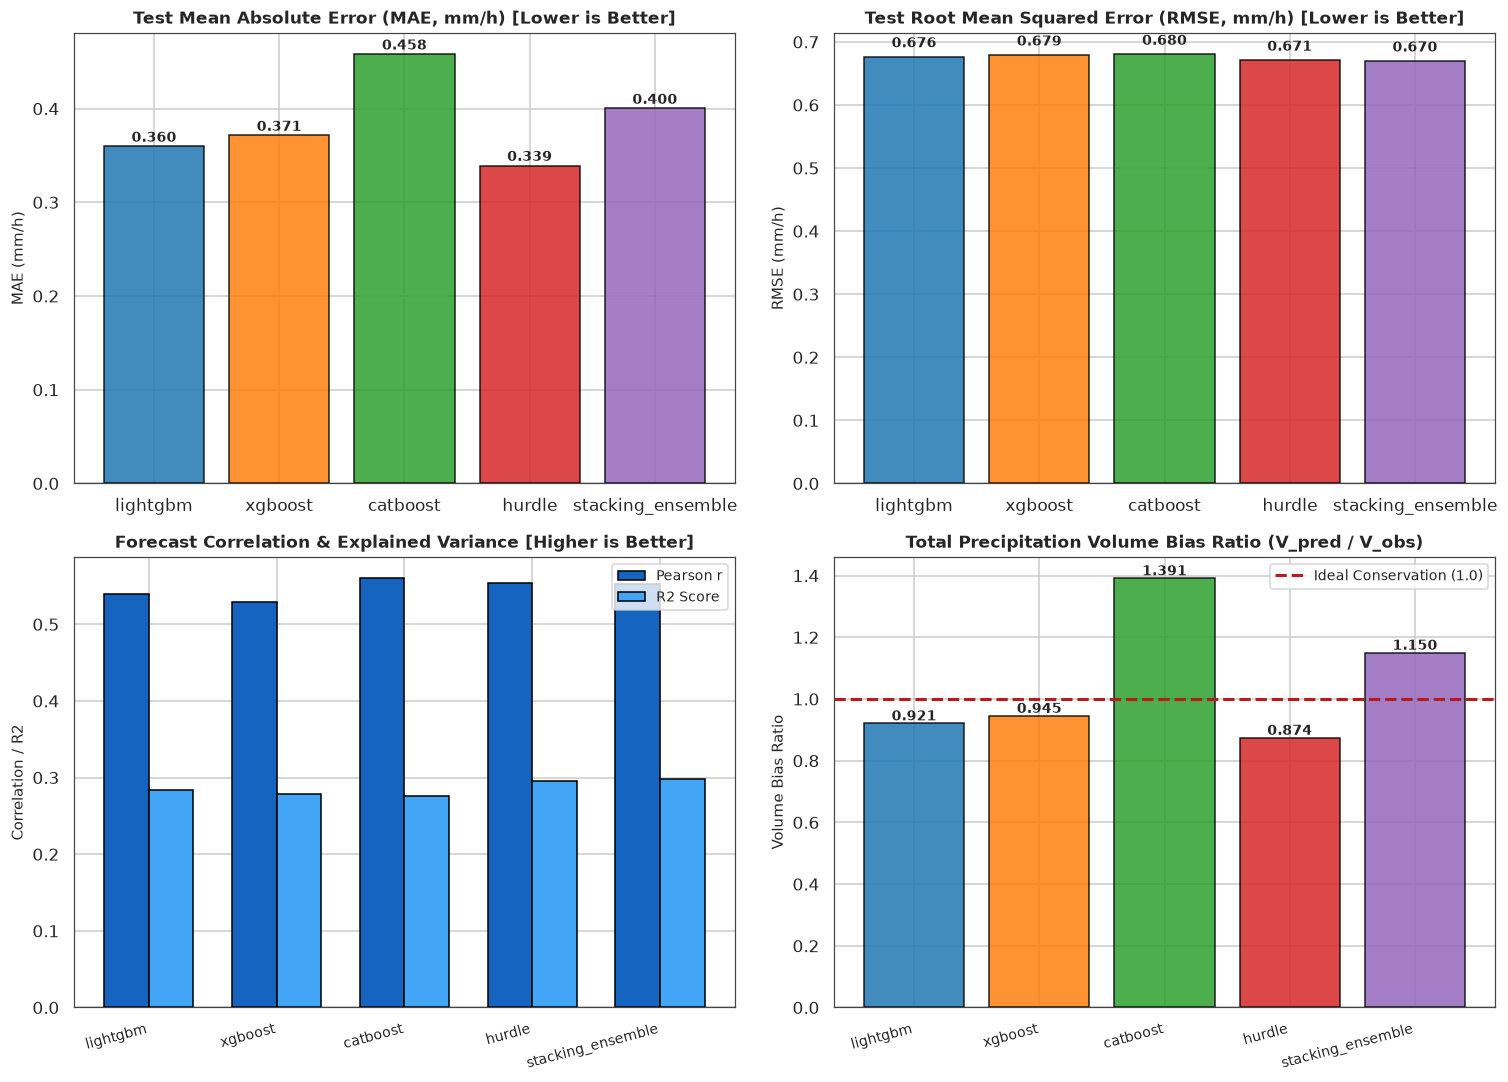


>>> Generating Contingency Threat Curves...


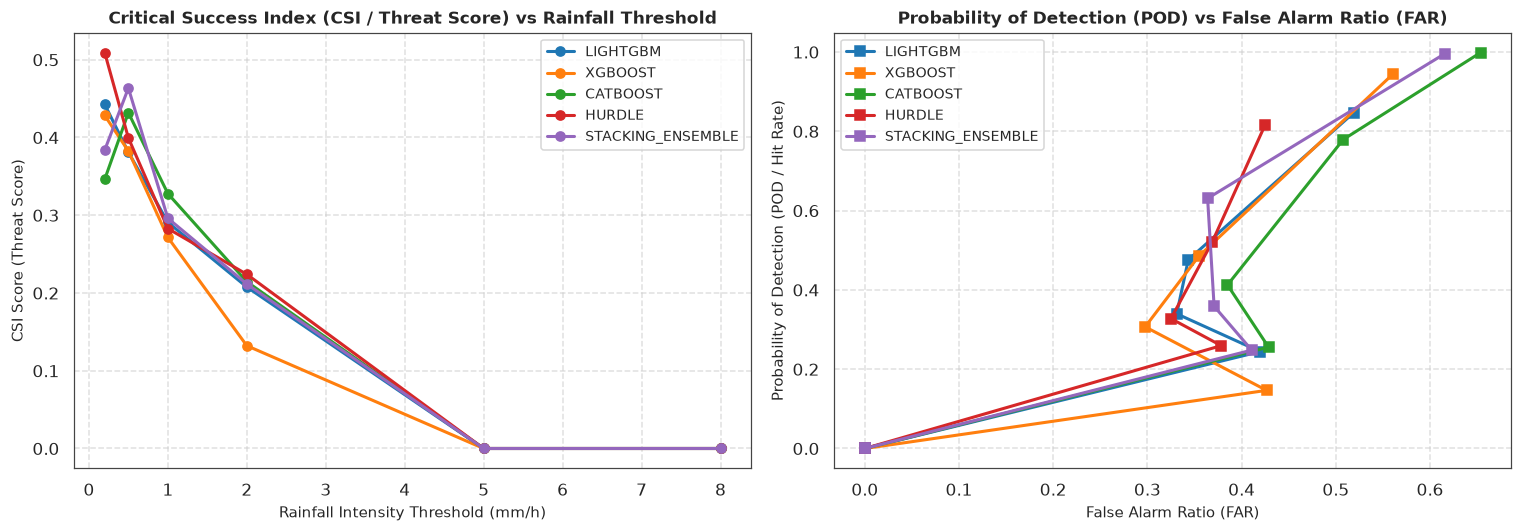


>>> Generating Test Precipitation Hydrograph...


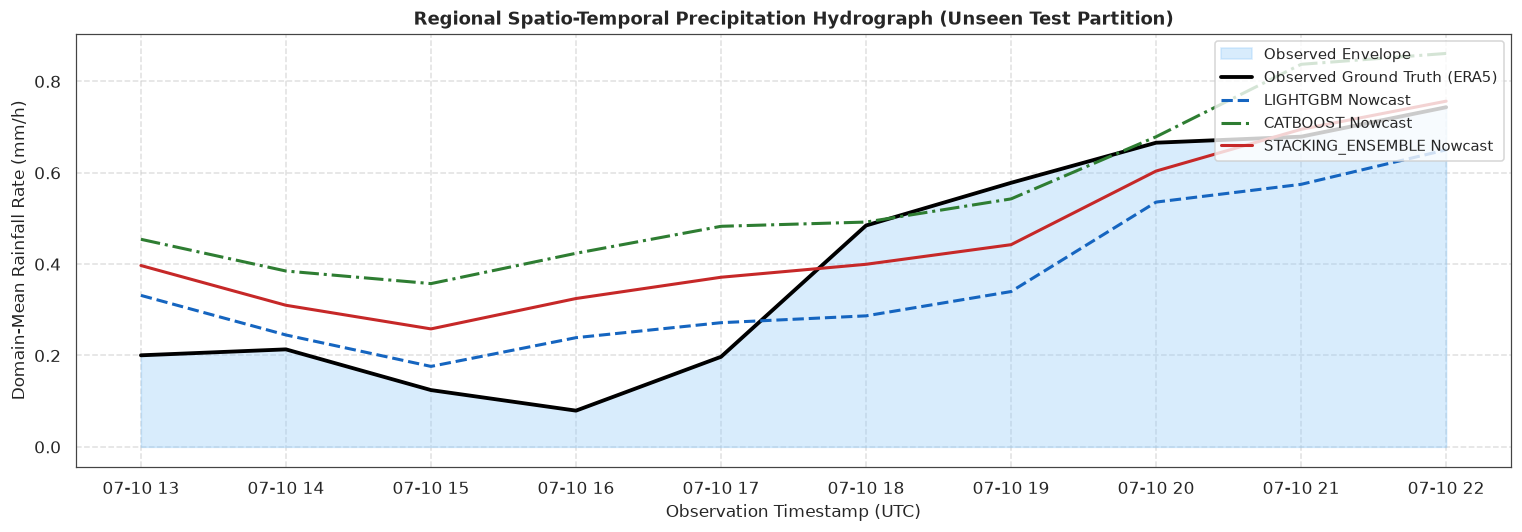


>>> Generating Residual Diagnostic Plots...


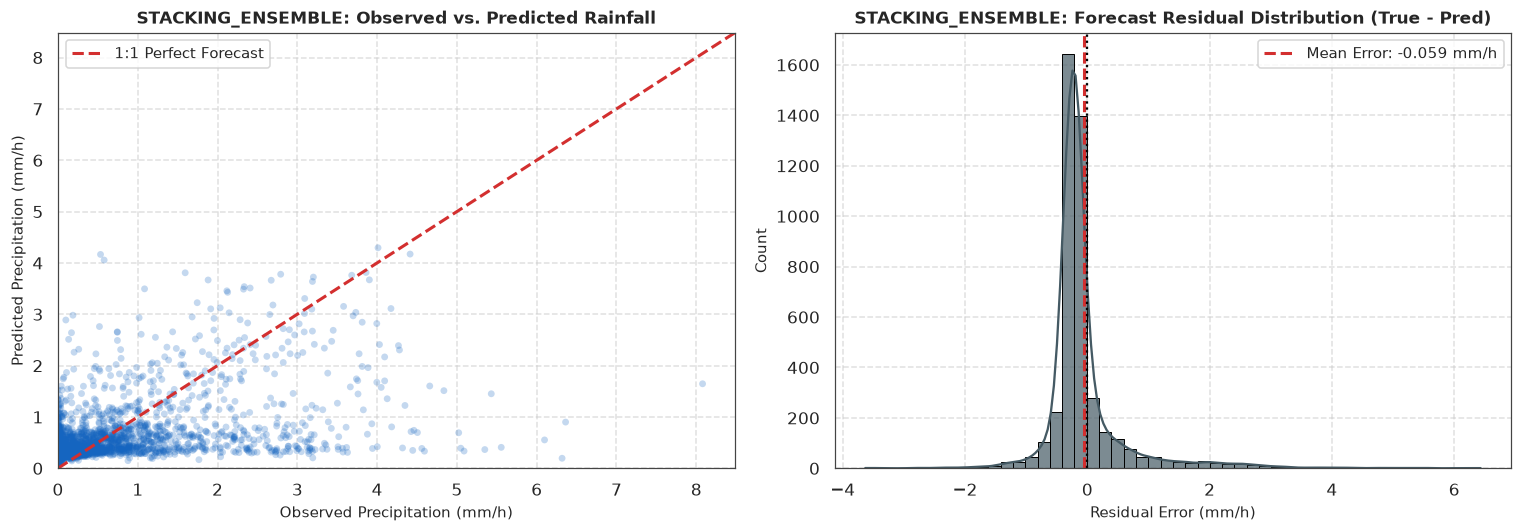


>>> Generating TreeSHAP Explainability Visualizations...
=== TreeSHAP Global Feature Attributions (Top Predictors) ===
             feature  mean_abs_shap
        precip_lag_1         1.1580
             doy_sin         0.2008
            hour_cos         0.1995
            hour_sin         0.1207
                 d2m         0.1081
        precip_lag_3         0.0668
                 v10         0.0467
                 u10         0.0326
 dewpoint_depression         0.0239
pressure_tendency_1h         0.0128


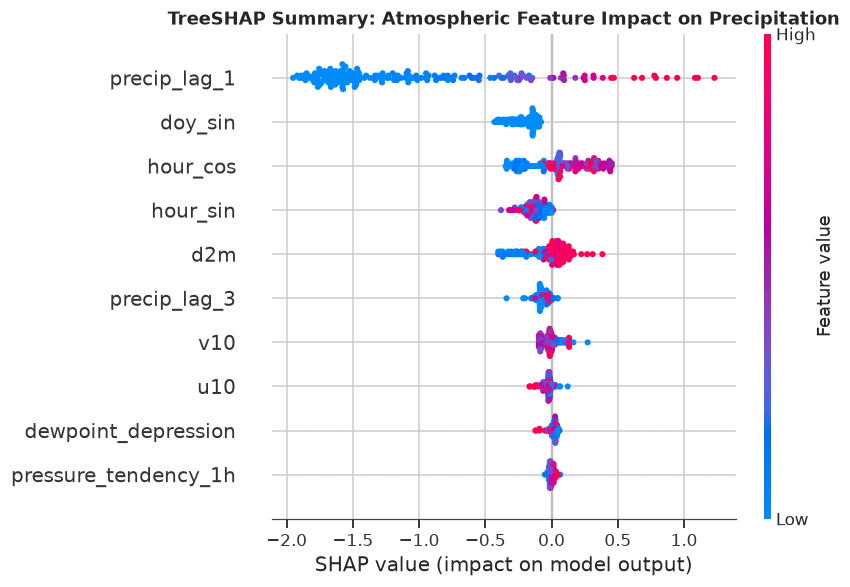


Project complete: All 12 scientific steps executed with full graphical EDA, training diagnostic curves, multi-model benchmark plots, and TreeSHAP explainability.


In [32]:
# Execution: Comprehensive Multi-Model Benchmarking, Verification, and Explainability
benchmark_records = []
for m_name, model in trained_models.items():
    print(f"\n--- Evaluating {m_name.upper()} on Unseen Test Partition ---")
    y_test_pred = model.predict(X_test)
    metrics = evaluate_continuous_forecast_metrics(y_test.values, y_test_pred)
    benchmark_records.append({
        "model": m_name,
        "mae_mm": metrics["mae_mm"],
        "rmse_mm": metrics["rmse_mm"],
        "r2_score": metrics["r2_score"],
        "pearson_r": metrics["pearson_r"],
        "spearman_rho": metrics["spearman_rho"],
        "volume_bias_ratio": metrics["volume_bias_ratio"]
    })

benchmark_df = pd.DataFrame(benchmark_records)
print("\n=== Comprehensive Multi-Model Performance Benchmark Table ===")
print(benchmark_df.to_string(index=False))

# Multi-threshold categorical threat evaluation
contingency_df = evaluate_multi_threshold_contingency(
    trained_models, X_test, y_test, thresholds=[0.2, 0.5, 1.0, 2.0, 5.0, 8.0]
)

# Plot 1: Multi-Model Benchmark Comparison (MAE, RMSE, Pearson r / R2, Volume Bias)
print("\n>>> Generating Model Benchmark Visualizations...")
plot_model_comparison_benchmark(benchmark_df, output_path="artifacts/plots/model_comparison_benchmark.png")

# Plot 2: Contingency Threat Curves (CSI & POD vs FAR)
print("\n>>> Generating Contingency Threat Curves...")
plot_contingency_threat_curves(contingency_df, output_path="artifacts/plots/contingency_threat_curves.png")

# Plot 3: Spatio-Temporal Hydrograph Time-Series Comparison
print("\n>>> Generating Test Precipitation Hydrograph...")
plot_observed_vs_predicted_hydrograph(test_df, y_test, trained_models, X_test, output_path="artifacts/plots/forecast_hydrograph.png")

# Plot 4: Residual & Error Diagnostics on Best Model (Stacking Ensemble / LightGBM)
print("\n>>> Generating Residual Diagnostic Plots...")
best_model_name = "stacking_ensemble" if "stacking_ensemble" in trained_models else "lightgbm"
y_best_pred = trained_models[best_model_name].predict(X_test)
plot_residual_diagnostics(y_test.values, y_best_pred, model_name=best_model_name.upper(), output_path="artifacts/plots/residual_diagnostics.png")

# Plot 5: TreeSHAP Explainability Analysis
print("\n>>> Generating TreeSHAP Explainability Visualizations...")
shap_sample = X_test.sample(min(200, len(X_test)), random_state=42)
shap_vals, shap_table = explain_model_with_shap(
    trained_models["lightgbm"], shap_sample, max_display=10, output_path="artifacts/plots/shap_summary.png"
)

print("\nProject complete: All 12 scientific steps executed with full graphical EDA, training diagnostic curves, multi-model benchmark plots, and TreeSHAP explainability.")
